In [2]:
x=1

In [11]:
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pertpy as pt
import scanpy as sc

sc.set_figure_params(vector_friendly=True, dpi=300)

In [12]:
alpha = 0.05  # SpatialFDR level (5%)

In [13]:
adata = sc.read_h5ad('/lustre/groups/ml01/workspace/anastasia.litinetskaya/code/multimil_reproducibility/pbmc/data/scvi_latent_3_cond_balanced.h5ad')
adata

AnnData object with n_obs × n_vars = 215678 × 30
    obs: 'sample_id', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'full_clustering', 'initial_clustering', 'Resample', 'Collection_Day', 'Sex', 'Age_interval', 'Swab_result', 'Status', 'Smoker', 'Status_on_day_collection', 'Status_on_day_collection_summary', 'Days_from_onset', 'Site', 'time_after_LPS', 'Worst_Clinical_Status', 'Outcome', 'patient_id', 'split0', 'split1', 'split2', 'split3', 'split4', '_scvi_batch', '_scvi_labels'
    uns: 'Age_interval_colors', 'Collection_Day_colors', 'Days_from_onset_colors', 'Outcome_colors', 'Resample_colors', 'Sex_colors', 'Site_colors', 'Smoker_colors', 'Status_colors', 'Status_on_day_collection_colors', 'Status_on_day_collection_summary_colors', 'Swab_result_colors', 'Worst_Clinical_Status_colors', 'full_clustering_colors', 'initial_clustering_colors', 'neighbors', 'patient_id_colors', 'sample_id_colors', 'split0_colors', 'split1_colors', 'split2_colors', 's

In [14]:
adata.obsm['X_scVI'] = adata.X.copy()

In [15]:
len(np.unique(adata.obs['sample_id']))

42

In [16]:
milo = pt.tl.Milo()
mdata = milo.load(adata)

In [18]:
mdata

MuData object with n_obs × n_vars = 215678 × 30
  2 modalities
    rna:	215678 x 30
      obs:	'sample_id', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'full_clustering', 'initial_clustering', 'Resample', 'Collection_Day', 'Sex', 'Age_interval', 'Swab_result', 'Status', 'Smoker', 'Status_on_day_collection', 'Status_on_day_collection_summary', 'Days_from_onset', 'Site', 'time_after_LPS', 'Worst_Clinical_Status', 'Outcome', 'patient_id', 'split0', 'split1', 'split2', 'split3', 'split4', '_scvi_batch', '_scvi_labels'
      uns:	'Age_interval_colors', 'Collection_Day_colors', 'Days_from_onset_colors', 'Outcome_colors', 'Resample_colors', 'Sex_colors', 'Site_colors', 'Smoker_colors', 'Status_colors', 'Status_on_day_collection_colors', 'Status_on_day_collection_summary_colors', 'Swab_result_colors', 'Worst_Clinical_Status_colors', 'full_clustering_colors', 'initial_clustering_colors', 'neighbors', 'patient_id_colors', 'sample_id_colors', 'split0_colors', 'split1_colors', 'split2_colors', 'split3_colors', 'split4_colors', 'time_after_LPS_colors', 'umap'
      obsm:	'X_umap', 'X_scVI'
      obsp:	'connectivities', 'distances'
    milo:	0 x 0

In [19]:
# following the tutorial https://pertpy.readthedocs.io/en/latest/tutorials/notebooks/milo.html,
# setting the k to be slightly higher than the number of samples
sc.pp.neighbors(mdata["rna"], use_rep="X_scVI", n_neighbors=50)

In [20]:
milo.make_nhoods(mdata["rna"], prop=0.1)

In [21]:
mdata["rna"].obsm["nhoods"]

<Compressed Sparse Row sparse matrix of dtype 'float32'
	with 1913549 stored elements and shape (215678, 13332)>

Text(0, 0.5, '# nhoods')

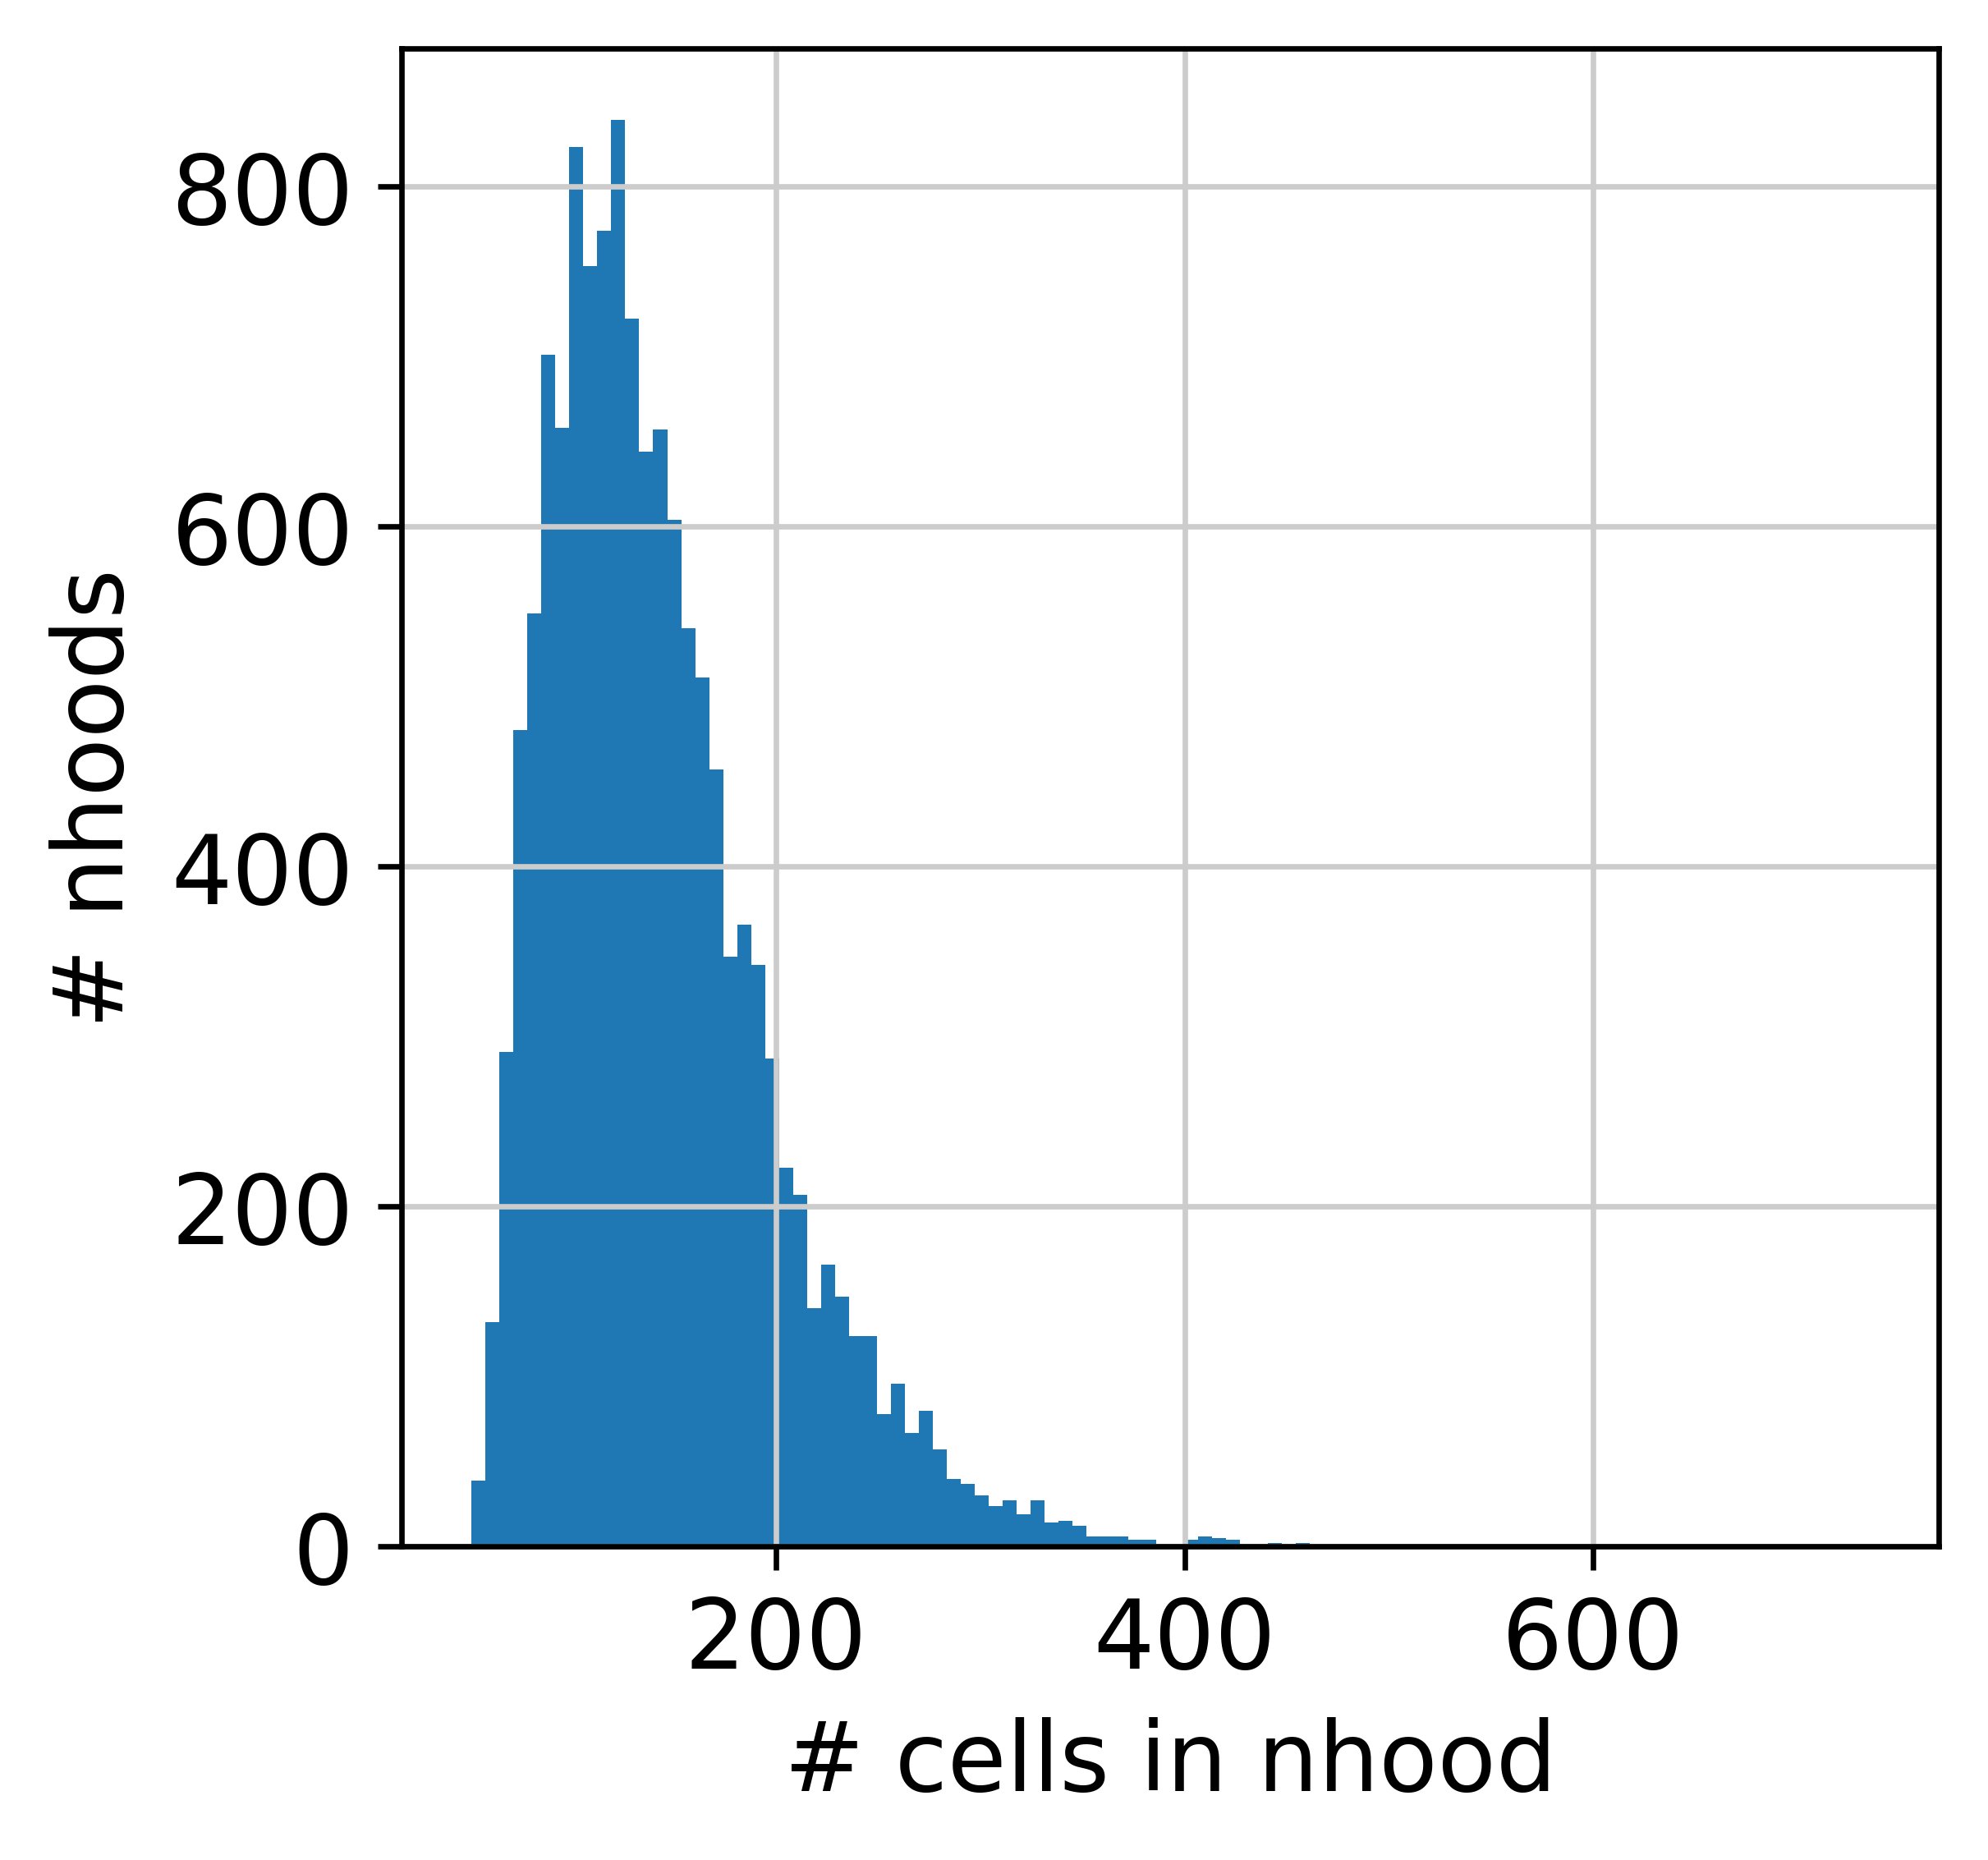

In [22]:
nhood_size = np.array(mdata["rna"].obsm["nhoods"].sum(0)).ravel()
plt.hist(nhood_size, bins=100)
plt.xlabel("# cells in nhood")
plt.ylabel("# nhoods")

In [23]:
mdata = milo.count_nhoods(mdata, sample_col="patient_id")

## severe healthy

In [24]:
# Reorder categories (by default, the last category is taken as the condition of interest)
mdata["rna"].obs['Status_on_day_collection_summary'] = mdata["rna"].obs['Status_on_day_collection_summary'].cat.reorder_categories(
    ['Healthy', 'Mild', 'Severe'], ordered=True
)
milo.da_nhoods(mdata, design="~Status_on_day_collection_summary", solver="pydeseq2",)

Fitting size factors...
/lustre/groups/ml01/workspace/anastasia.litinetskaya/mambaforge/envs/milo/lib/python3.12/site-packages/pydeseq2/dds.py:532: UserWarning: Every gene contains at least one zero, cannot compute log geometric means. Switching to iterative mode.
  self.fit_size_factors(


Using None as control genes, passed at DeseqDataSet initialization


Fitting dispersions...
... done in 2.15 seconds.

Fitting MAP dispersions...
... done in 1.73 seconds.

Fitting dispersions...
... done in 2.05 seconds.

Fitting MAP dispersions...
... done in 1.78 seconds.

Fitting dispersions...
... done in 2.31 seconds.

Fitting MAP dispersions...
... done in 1.77 seconds.

Fitting dispersions...
... done in 2.02 seconds.

Fitting MAP dispersions...
... done in 1.77 seconds.

Fitting dispersions...
... done in 2.08 seconds.

Fitting MAP dispersions...
... done in 1.78 seconds.

Fitting dispersions...
... done in 2.06 seconds.

Fitting MAP dispersions...
... done in 1.79 seconds.

Fitting dispersions...
... done in 2.30 seconds.

Fitting MAP dispersions...
... done in 1.97 seconds.

Fitting dispersions...
... done in 2.58 seconds.

Fitting MAP dispersions...
... done in 1.83 seconds.

Fitting dispersions...
... done in 2.21 seconds.

Fitting MAP dispersions...
... done in 1.79 seconds.

Fitting dispersions...
... done in 2.43 seconds.

Fitting MAP di

Log2 fold change & Wald test p-value: Status_on_day_collection_summary Severe vs Healthy
        baseMean  log2FoldChange     lfcSE      stat    pvalue      padj
0       4.239880       -0.552421  1.100250 -0.502087  0.615606  0.740948
1       3.718632       -2.342958  0.898313 -2.608176  0.009103  0.048363
2       1.531120       -0.291609  1.017465 -0.286604  0.774416  0.853605
3       2.729174       -2.145634  0.750732 -2.858057  0.004262  0.032061
4      22.286343       -1.149925  0.878076 -1.309596  0.190333  0.332062
...          ...             ...       ...       ...       ...       ...
13327   5.918860       -1.124951  1.014469 -1.108906  0.267471  0.422846
13328   1.057179       -1.757162  0.971491 -1.808728  0.070493       NaN
13329  22.846750       -2.258178  1.015675 -2.223328  0.026194  0.090532
13330   7.032147       -0.160517  0.867530 -0.185028  0.853207  0.909896
13331   1.856053        1.065518  0.979188  1.088164  0.276523  0.432701

[13332 rows x 6 columns]


## Severe - Healthy

In [25]:
milo.da_nhoods(mdata, design="~Status_on_day_collection_summary", model_contrasts="Status_on_day_collection_summarySevere-Status_on_day_collection_summaryHealthy", solver="pydeseq2")

Fitting size factors...
/lustre/groups/ml01/workspace/anastasia.litinetskaya/mambaforge/envs/milo/lib/python3.12/site-packages/pydeseq2/dds.py:532: UserWarning: Every gene contains at least one zero, cannot compute log geometric means. Switching to iterative mode.
  self.fit_size_factors(


Using None as control genes, passed at DeseqDataSet initialization


Fitting dispersions...
... done in 2.50 seconds.

Fitting MAP dispersions...
... done in 1.74 seconds.

Fitting dispersions...
... done in 2.01 seconds.

Fitting MAP dispersions...
... done in 1.75 seconds.

Fitting dispersions...
... done in 2.07 seconds.

Fitting MAP dispersions...
... done in 1.75 seconds.

Fitting dispersions...
... done in 2.34 seconds.

Fitting MAP dispersions...
... done in 1.72 seconds.

Fitting dispersions...
... done in 2.01 seconds.

Fitting MAP dispersions...
... done in 1.78 seconds.

Fitting dispersions...
... done in 1.98 seconds.

Fitting MAP dispersions...
... done in 1.74 seconds.

Fitting dispersions...
... done in 2.15 seconds.

Fitting MAP dispersions...
... done in 1.88 seconds.

Fitting dispersions...
... done in 2.40 seconds.

Fitting MAP dispersions...
... done in 1.75 seconds.

Fitting dispersions...
... done in 2.25 seconds.

Fitting MAP dispersions...
... done in 1.77 seconds.

Fitting dispersions...
... done in 2.11 seconds.

Fitting MAP di

Log2 fold change & Wald test p-value: Status_on_day_collection_summary Severe vs Healthy
        baseMean  log2FoldChange     lfcSE      stat    pvalue      padj
0       4.239880       -0.552421  1.100250 -0.502087  0.615606  0.740948
1       3.718632       -2.342958  0.898313 -2.608176  0.009103  0.048363
2       1.531120       -0.291609  1.017465 -0.286604  0.774416  0.853605
3       2.729174       -2.145634  0.750732 -2.858057  0.004262  0.032061
4      22.286343       -1.149925  0.878076 -1.309596  0.190333  0.332062
...          ...             ...       ...       ...       ...       ...
13327   5.918860       -1.124951  1.014469 -1.108906  0.267471  0.422846
13328   1.057179       -1.757162  0.971491 -1.808728  0.070493       NaN
13329  22.846750       -2.258178  1.015675 -2.223328  0.026194  0.090532
13330   7.032147       -0.160517  0.867530 -0.185028  0.853207  0.909896
13331   1.856053        1.065518  0.979188  1.088164  0.276523  0.432701

[13332 rows x 6 columns]


... done in 1.88 seconds.



In [26]:
mdata["milo"].var

,index_cell,kth_distance,SpatialFDR,logCPM,logFC,PValue,FDR
0,AAACCTGAGACCACGA-newcastle65,2.635731,0.755838,4.239880,-0.552421,0.615606,0.740948
1,AAACCTGGTTCGCGAC-newcastle65,2.423467,0.056633,3.718632,-2.342958,0.009103,0.048363
2,AAACGGGGTTACAGAA-newcastle65,2.719470,0.863458,1.531120,-0.291609,0.774416,0.853605
3,AAACGGGTCATCGGAT-newcastle65,2.575334,0.037592,2.729174,-2.145634,0.004262,0.032061
4,AAAGCAACAGTTAACC-newcastle65,2.436827,0.357834,22.286343,-1.149925,0.190333,0.332062
...,...,...,...,...,...,...,...
13327,BGCV15_TGCACCTTCGCCAGCA-1,2.510799,0.447993,5.918860,-1.124951,0.267471,0.422846
13328,BGCV15_TGTGGTATCAGTTTGG-1,2.714978,0.189893,1.057179,-1.757162,0.070493,NaN
13329,BGCV15_TTAGGCAAGCTAGCCC-1,2.534584,0.105081,22.846750,-2.258178,0.026194,0.090532
13330,BGCV15_TTCTACATCCGCGGTA-1,2.647649,0.915320,7.032147,-0.160517,0.853207,0.909896


In [27]:
# save milo testing results
mdata["milo"].var.to_csv('milo_severe_vs_healthy.csv')

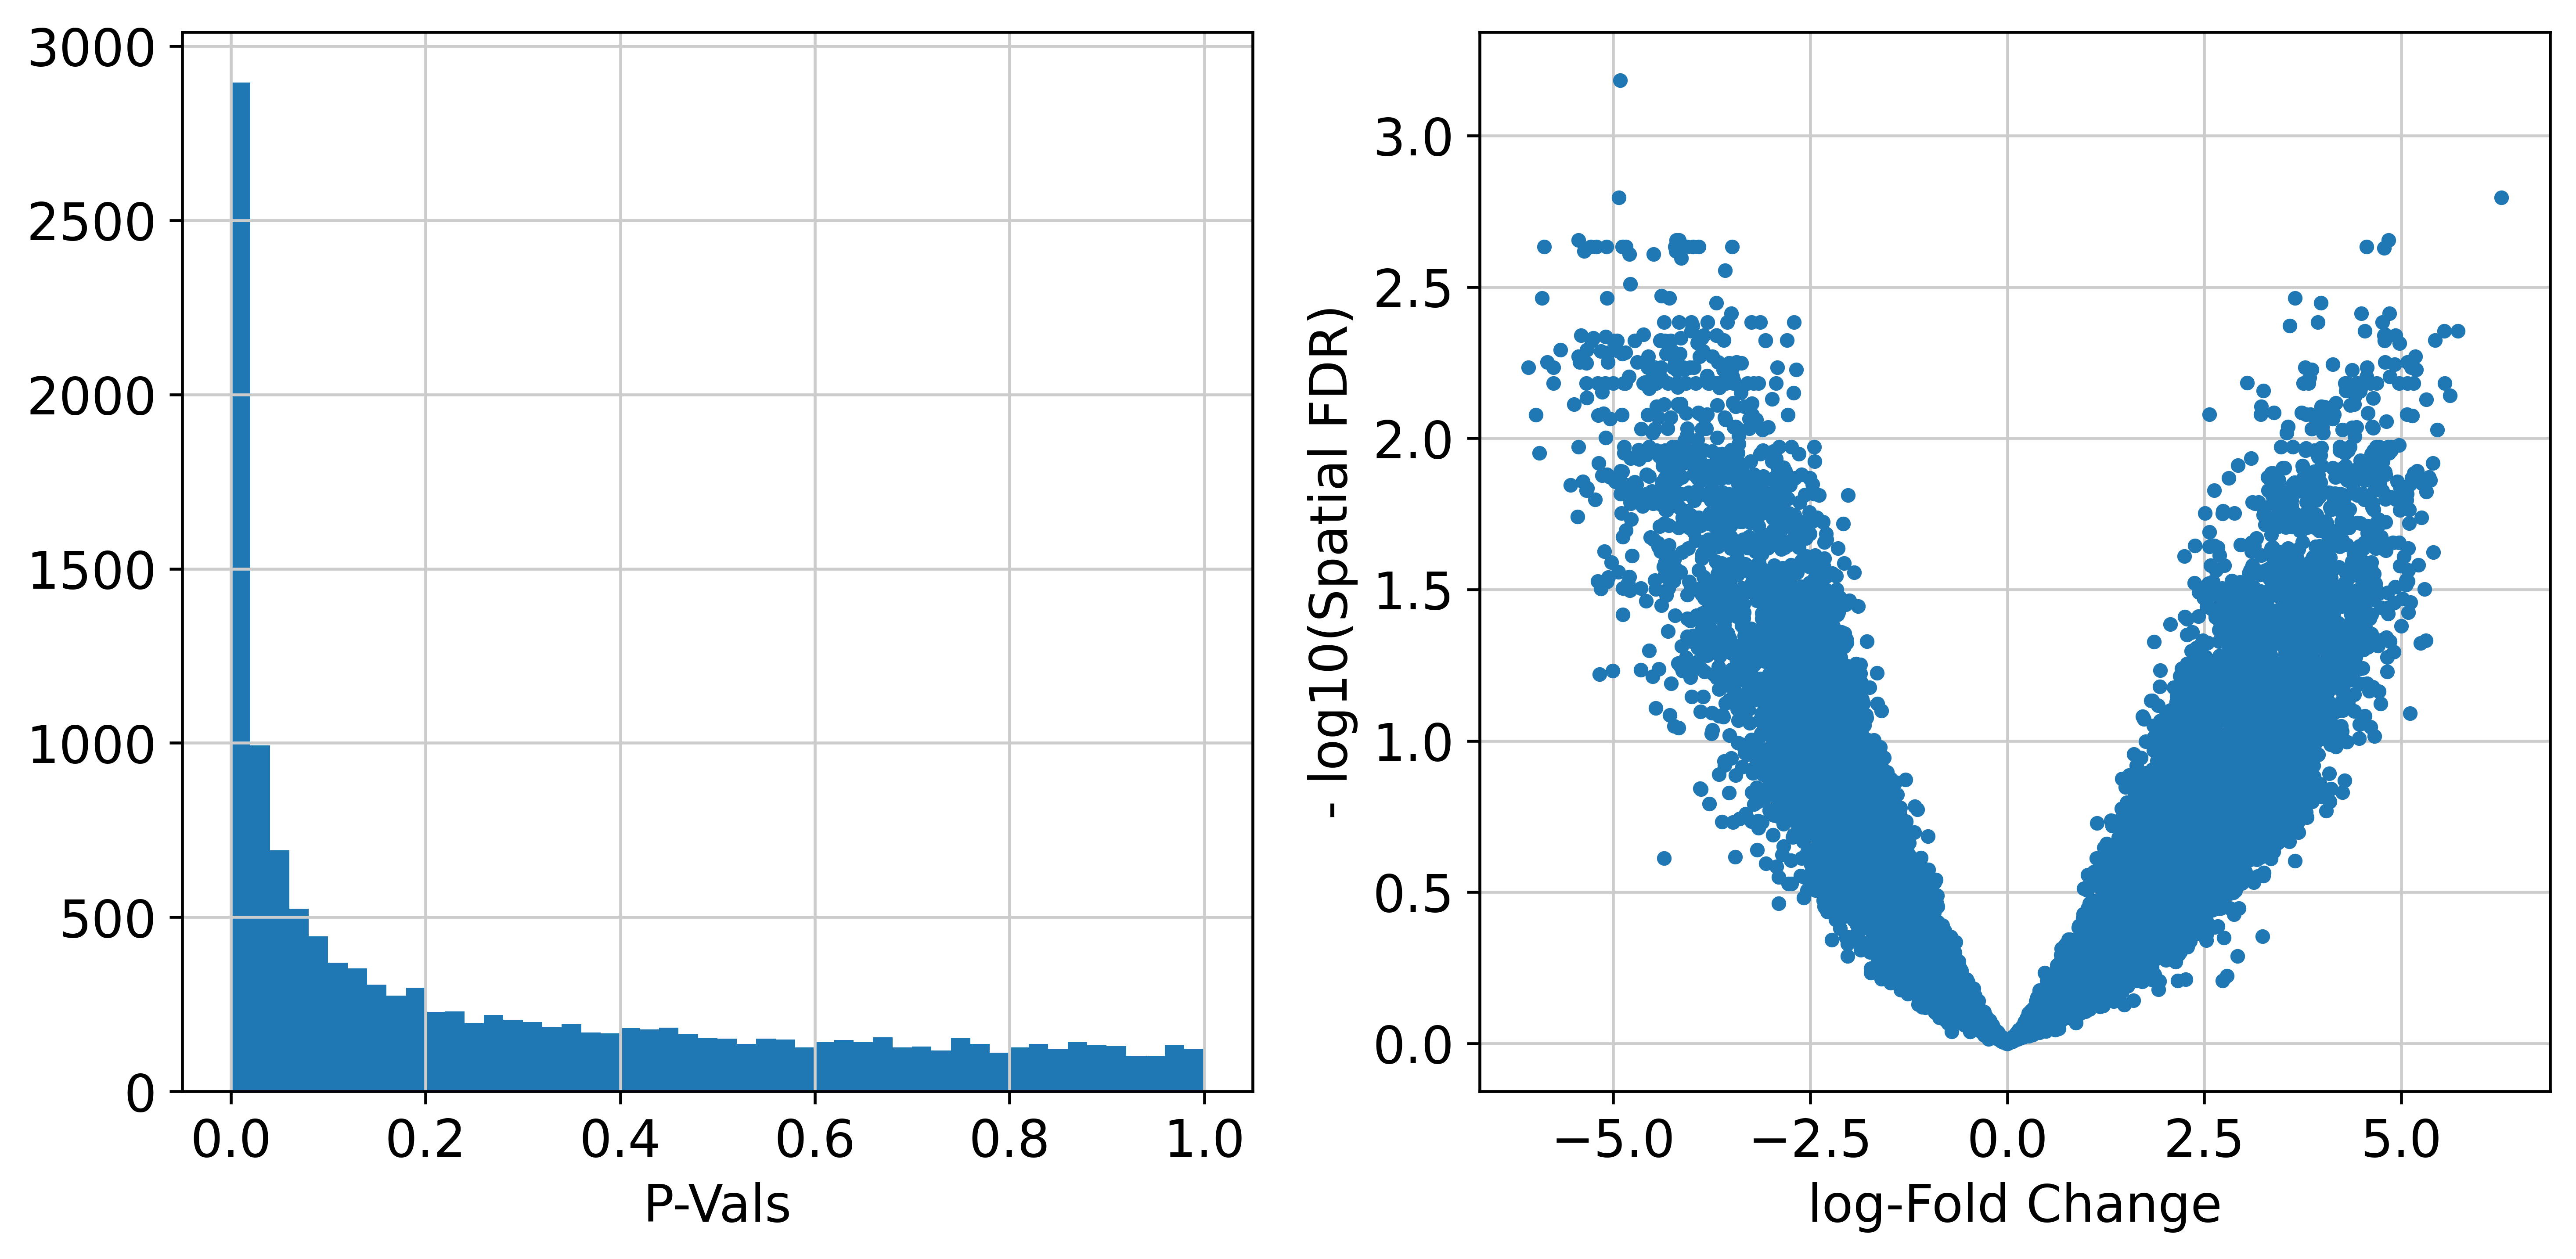

In [28]:
old_figsize = plt.rcParams["figure.figsize"]
plt.rcParams["figure.figsize"] = [10, 5]
plt.subplot(1, 2, 1)
plt.hist(mdata["milo"].var.PValue, bins=50)
plt.xlabel("P-Vals")
plt.subplot(1, 2, 2)
plt.plot(mdata["milo"].var.logFC, -np.log10(mdata["milo"].var.SpatialFDR), ".")
plt.xlabel("log-Fold Change")
plt.ylabel("- log10(Spatial FDR)")
plt.tight_layout()
plt.rcParams["figure.figsize"] = old_figsize

In [29]:
milo.build_nhood_graph(mdata)

In [30]:
plt.rcParams["figure.figsize"] = [4, 4]
milo.plot_nhood_graph(
    mdata,
    alpha=alpha,
    min_size=1,
    save='_milo_severe_vs_healthy.svg',
)

saving figure to file figures/X_milo_graph_milo_severe_vs_healthy.svg


In [31]:
milo.annotate_nhoods(mdata, anno_col="initial_clustering")

Text(0.5, 0, 'celltype fraction')

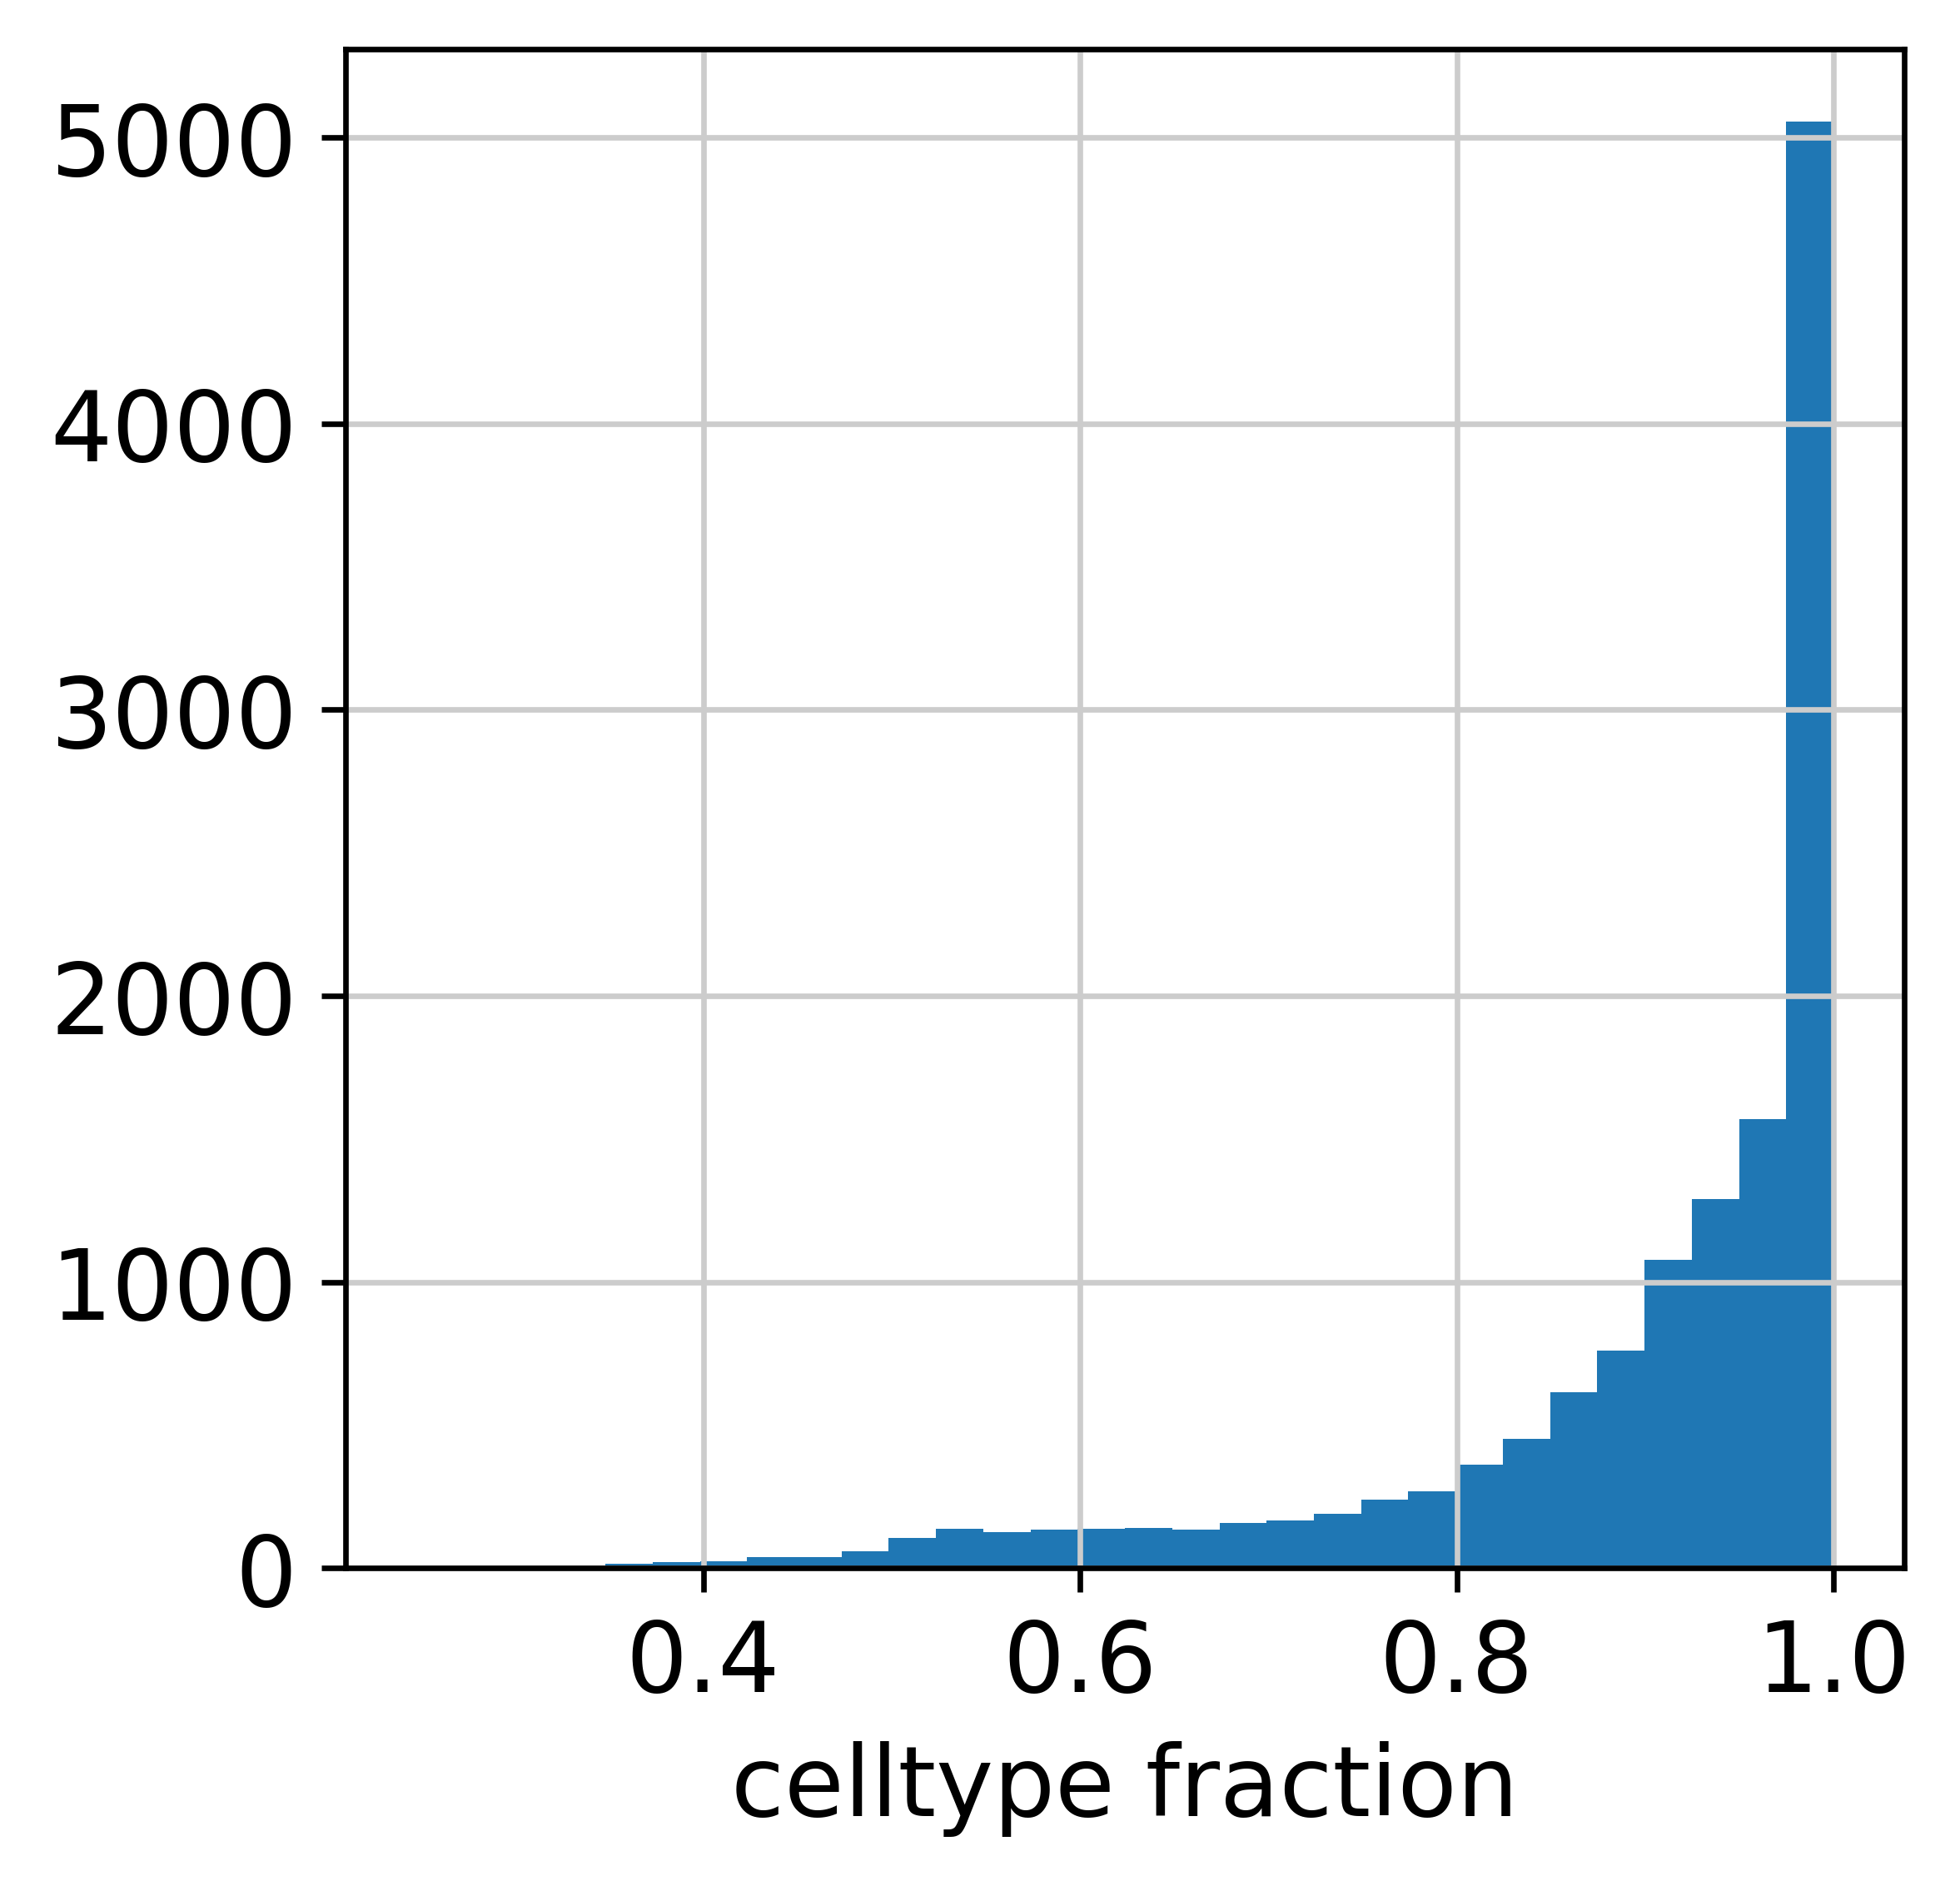

In [32]:
plt.hist(mdata["milo"].var["nhood_annotation_frac"], bins=30)
plt.xlabel("celltype fraction")

In [33]:
mdata["milo"].var["nhood_annotation"] = mdata["milo"].var["nhood_annotation"].cat.add_categories("Mixed")
mdata["milo"].var.loc[mdata["milo"].var["nhood_annotation_frac"] < 0.8, "nhood_annotation"] = "Mixed"

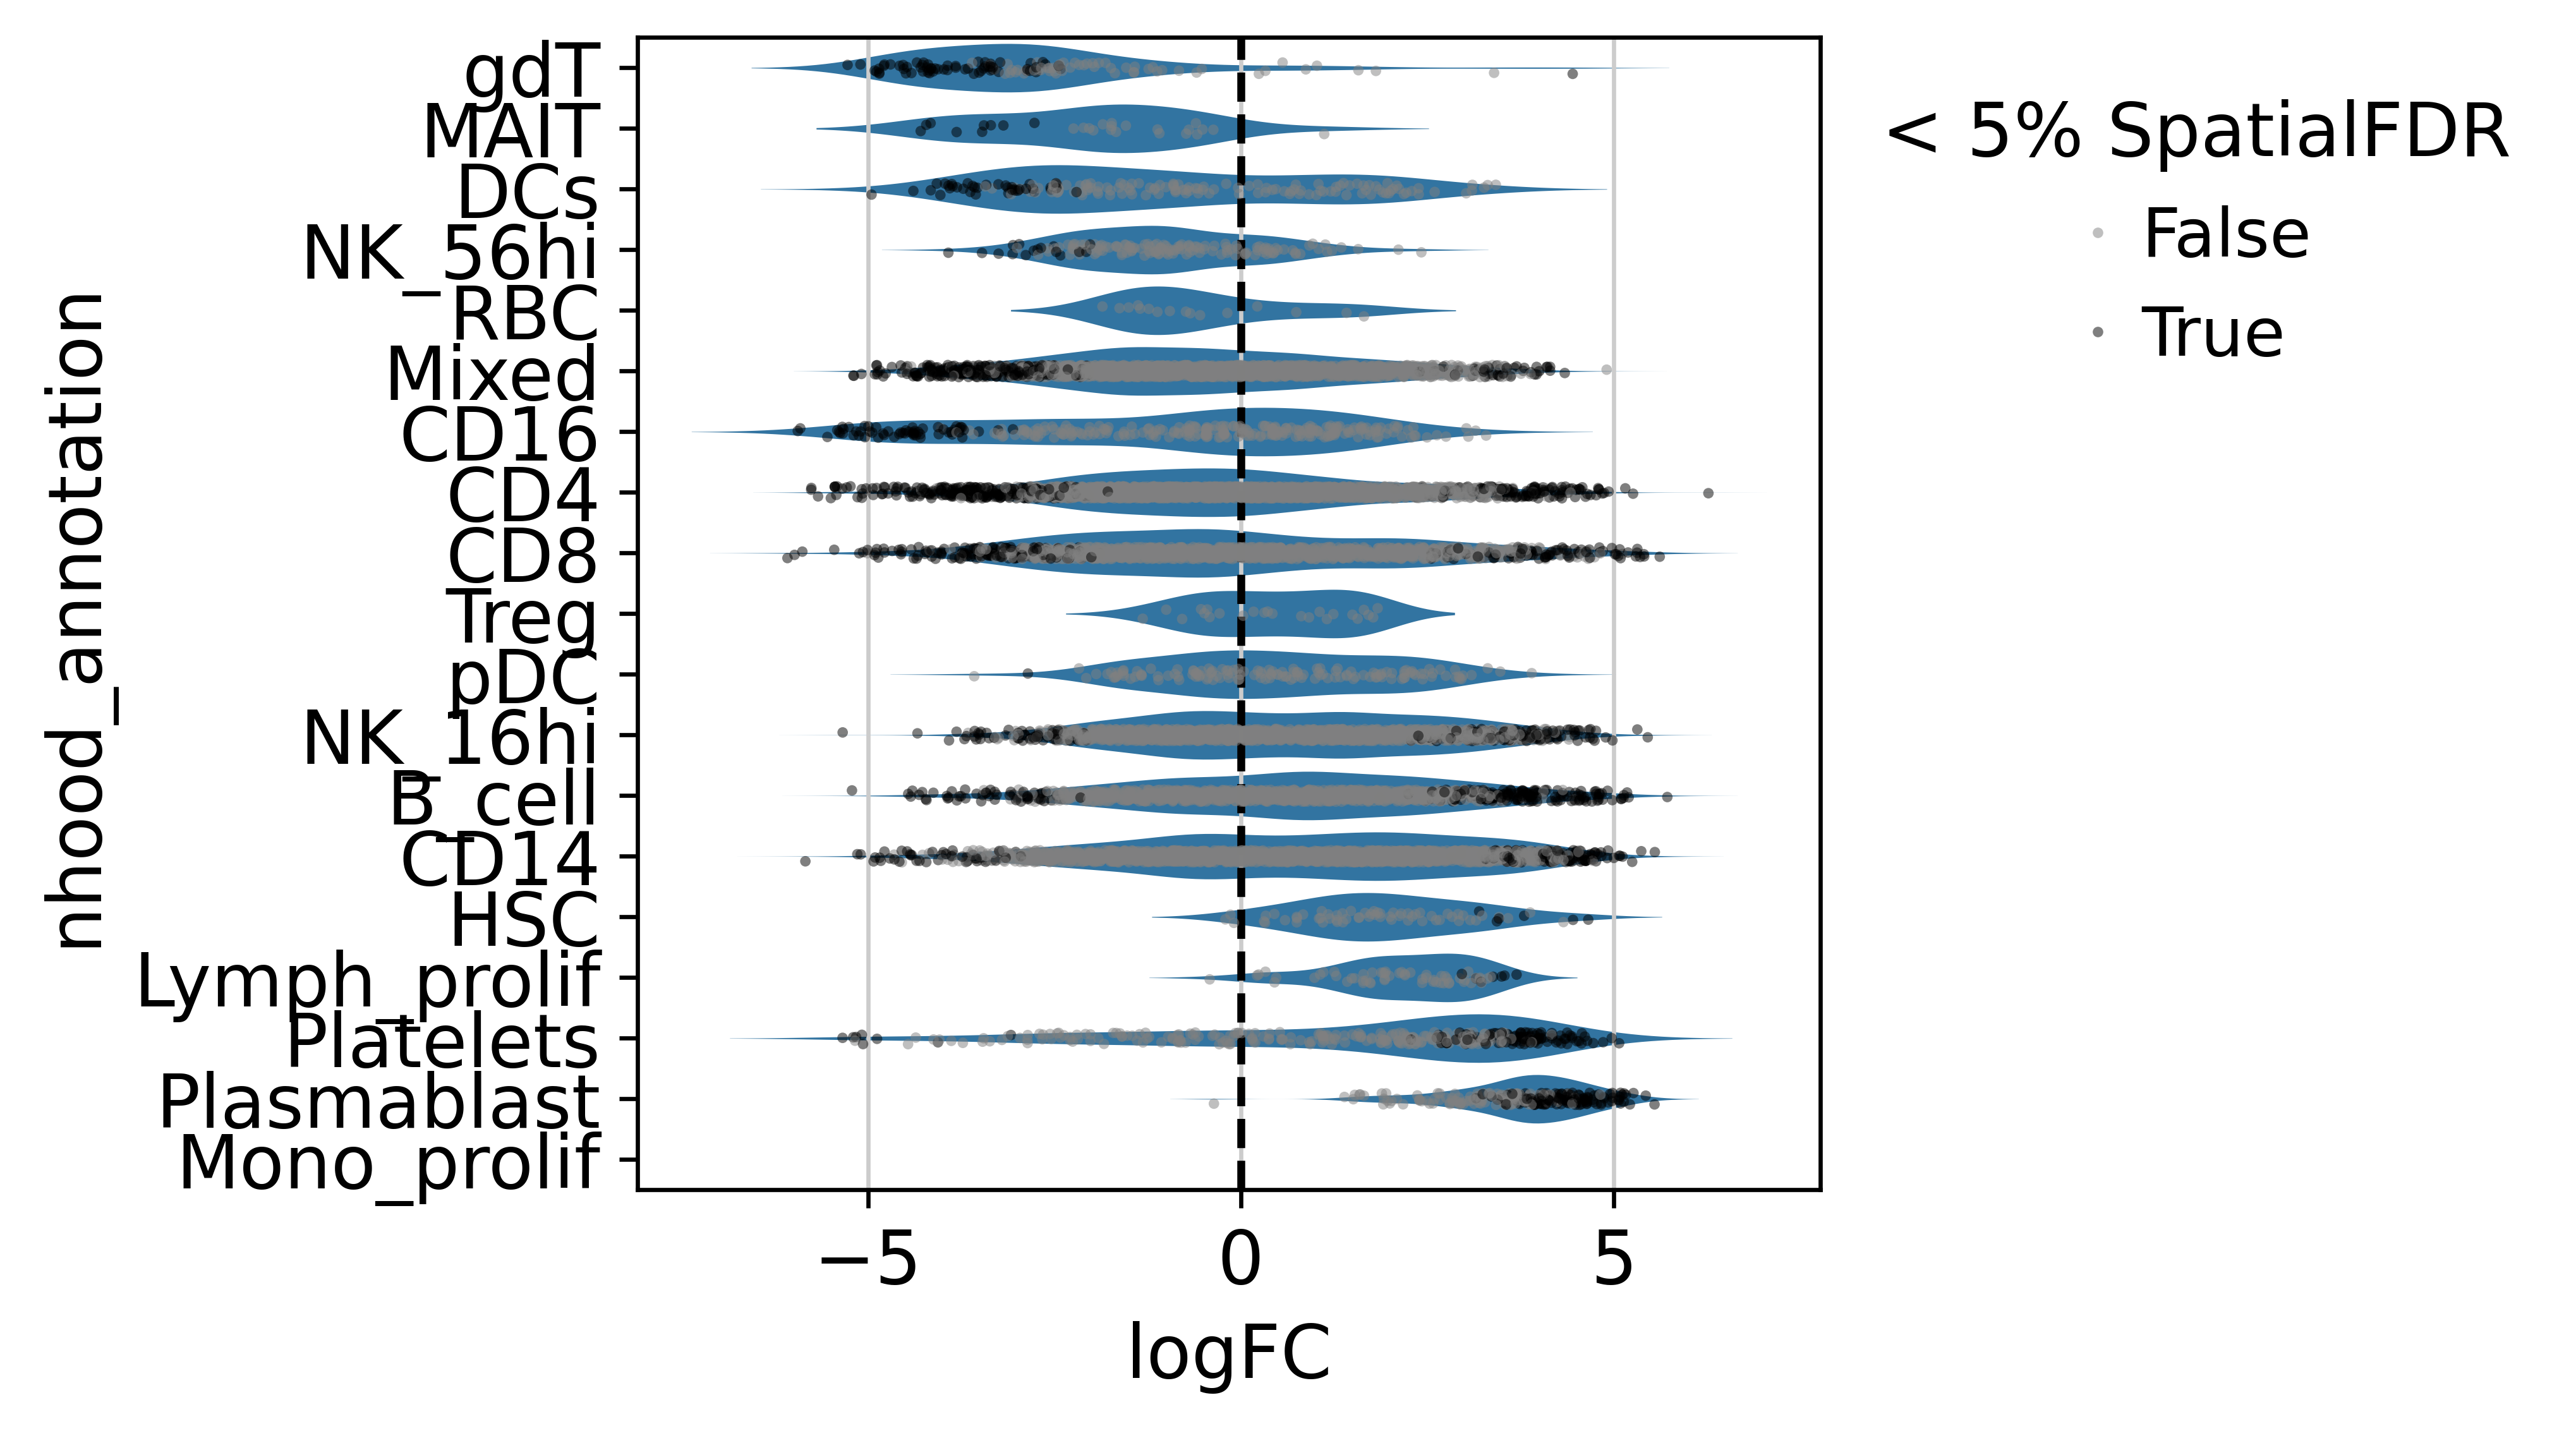

In [34]:
milo.plot_da_beeswarm(mdata, alpha=alpha, return_fig=True)
plt.savefig('figures/milo_severe_vs_healthy_beeswarm.svg', bbox_inches='tight', dpi=300)

## Severe - Mild

In [35]:
milo.da_nhoods(mdata, design="~Status_on_day_collection_summary", model_contrasts="Status_on_day_collection_summarySevere-Status_on_day_collection_summaryMild", solver="pydeseq2")

Fitting size factors...
/lustre/groups/ml01/workspace/anastasia.litinetskaya/mambaforge/envs/milo/lib/python3.12/site-packages/pydeseq2/dds.py:532: UserWarning: Every gene contains at least one zero, cannot compute log geometric means. Switching to iterative mode.
  self.fit_size_factors(


Using None as control genes, passed at DeseqDataSet initialization


Fitting dispersions...
... done in 2.22 seconds.

Fitting MAP dispersions...
... done in 2.84 seconds.



Fitting dispersions...
... done in 2.04 seconds.

Fitting MAP dispersions...
... done in 1.77 seconds.

Fitting dispersions...
... done in 2.03 seconds.

Fitting MAP dispersions...
... done in 1.80 seconds.

Fitting dispersions...
... done in 2.03 seconds.

Fitting MAP dispersions...
... done in 1.74 seconds.

Fitting dispersions...
... done in 3.86 seconds.

Fitting MAP dispersions...
... done in 1.81 seconds.

Fitting dispersions...
... done in 2.05 seconds.

Fitting MAP dispersions...
... done in 1.76 seconds.

Fitting dispersions...
... done in 1.99 seconds.

Fitting MAP dispersions...
... done in 1.76 seconds.

Fitting dispersions...
... done in 2.02 seconds.

Fitting MAP dispersions...
... done in 2.96 seconds.

Fitting dispersions...
... done in 1.98 seconds.

Fitting MAP dispersions...
... done in 1.92 seconds.

Fitting dispersions...
... done in 2.00 seconds.

Fitting MAP dispersions...
... done in 1.77 seconds.

Iterative size factor fitting did not converge.
... done in 346.

Log2 fold change & Wald test p-value: Status_on_day_collection_summary Severe vs Mild
        baseMean  log2FoldChange     lfcSE      stat    pvalue      padj
0       4.239880       -1.859153  1.087189 -1.710055  0.087256       NaN
1       3.718632       -1.319521  0.912688 -1.445753  0.148247       NaN
2       1.531120        1.115431  1.052240  1.060053  0.289120       NaN
3       2.729174       -2.221009  0.743171 -2.988558  0.002803       NaN
4      22.286343        0.879587  0.903672  0.973348  0.330381  0.776426
...          ...             ...       ...       ...       ...       ...
13327   5.918860       -1.334213  1.014345 -1.315343  0.188395       NaN
13328   1.057179       -1.397363  0.967338 -1.444545  0.148586       NaN
13329  22.846750        0.216991  1.045765  0.207495  0.835624  0.959252
13330   7.032147        1.219661  0.889631  1.370975  0.170383       NaN
13331   1.856053       -0.879104  0.889609 -0.988191  0.323059       NaN

[13332 rows x 6 columns]


... done in 1.84 seconds.



In [36]:
mdata["milo"].var

,index_cell,kth_distance,SpatialFDR,Nhood_size,nhood_annotation,nhood_annotation_frac,logCPM,logFC,PValue,FDR
0,AAACCTGAGACCACGA-newcastle65,2.635731,0.490696,172.0,CD4,0.918605,4.239880,-1.859153,0.087256,NaN
1,AAACCTGGTTCGCGAC-newcastle65,2.423467,0.582077,229.0,CD4,0.960699,3.718632,-1.319521,0.148247,NaN
2,AAACGGGGTTACAGAA-newcastle65,2.719470,0.702635,74.0,CD4,0.864865,1.531120,1.115431,0.289120,NaN
3,AAACGGGTCATCGGAT-newcastle65,2.575334,0.198570,203.0,CD4,0.916256,2.729174,-2.221009,0.002803,NaN
4,AAAGCAACAGTTAACC-newcastle65,2.436827,0.733002,471.0,NK_16hi,0.993631,22.286343,0.879587,0.330381,0.776426
...,...,...,...,...,...,...,...,...,...,...
13327,BGCV15_TGCACCTTCGCCAGCA-1,2.510799,0.627600,163.0,CD4,0.914110,5.918860,-1.334213,0.188395,NaN
13328,BGCV15_TGTGGTATCAGTTTGG-1,2.714978,0.582077,83.0,CD4,0.963855,1.057179,-1.397363,0.148586,NaN
13329,BGCV15_TTAGGCAAGCTAGCCC-1,2.534584,0.957608,362.0,NK_16hi,0.941989,22.846750,0.216991,0.835624,0.959252
13330,BGCV15_TTCTACATCCGCGGTA-1,2.647649,0.607655,170.0,NK_16hi,1.000000,7.032147,1.219661,0.170383,NaN


In [37]:
# save milo testing results
mdata["milo"].var.to_csv('milo_severe_vs_mild.csv')

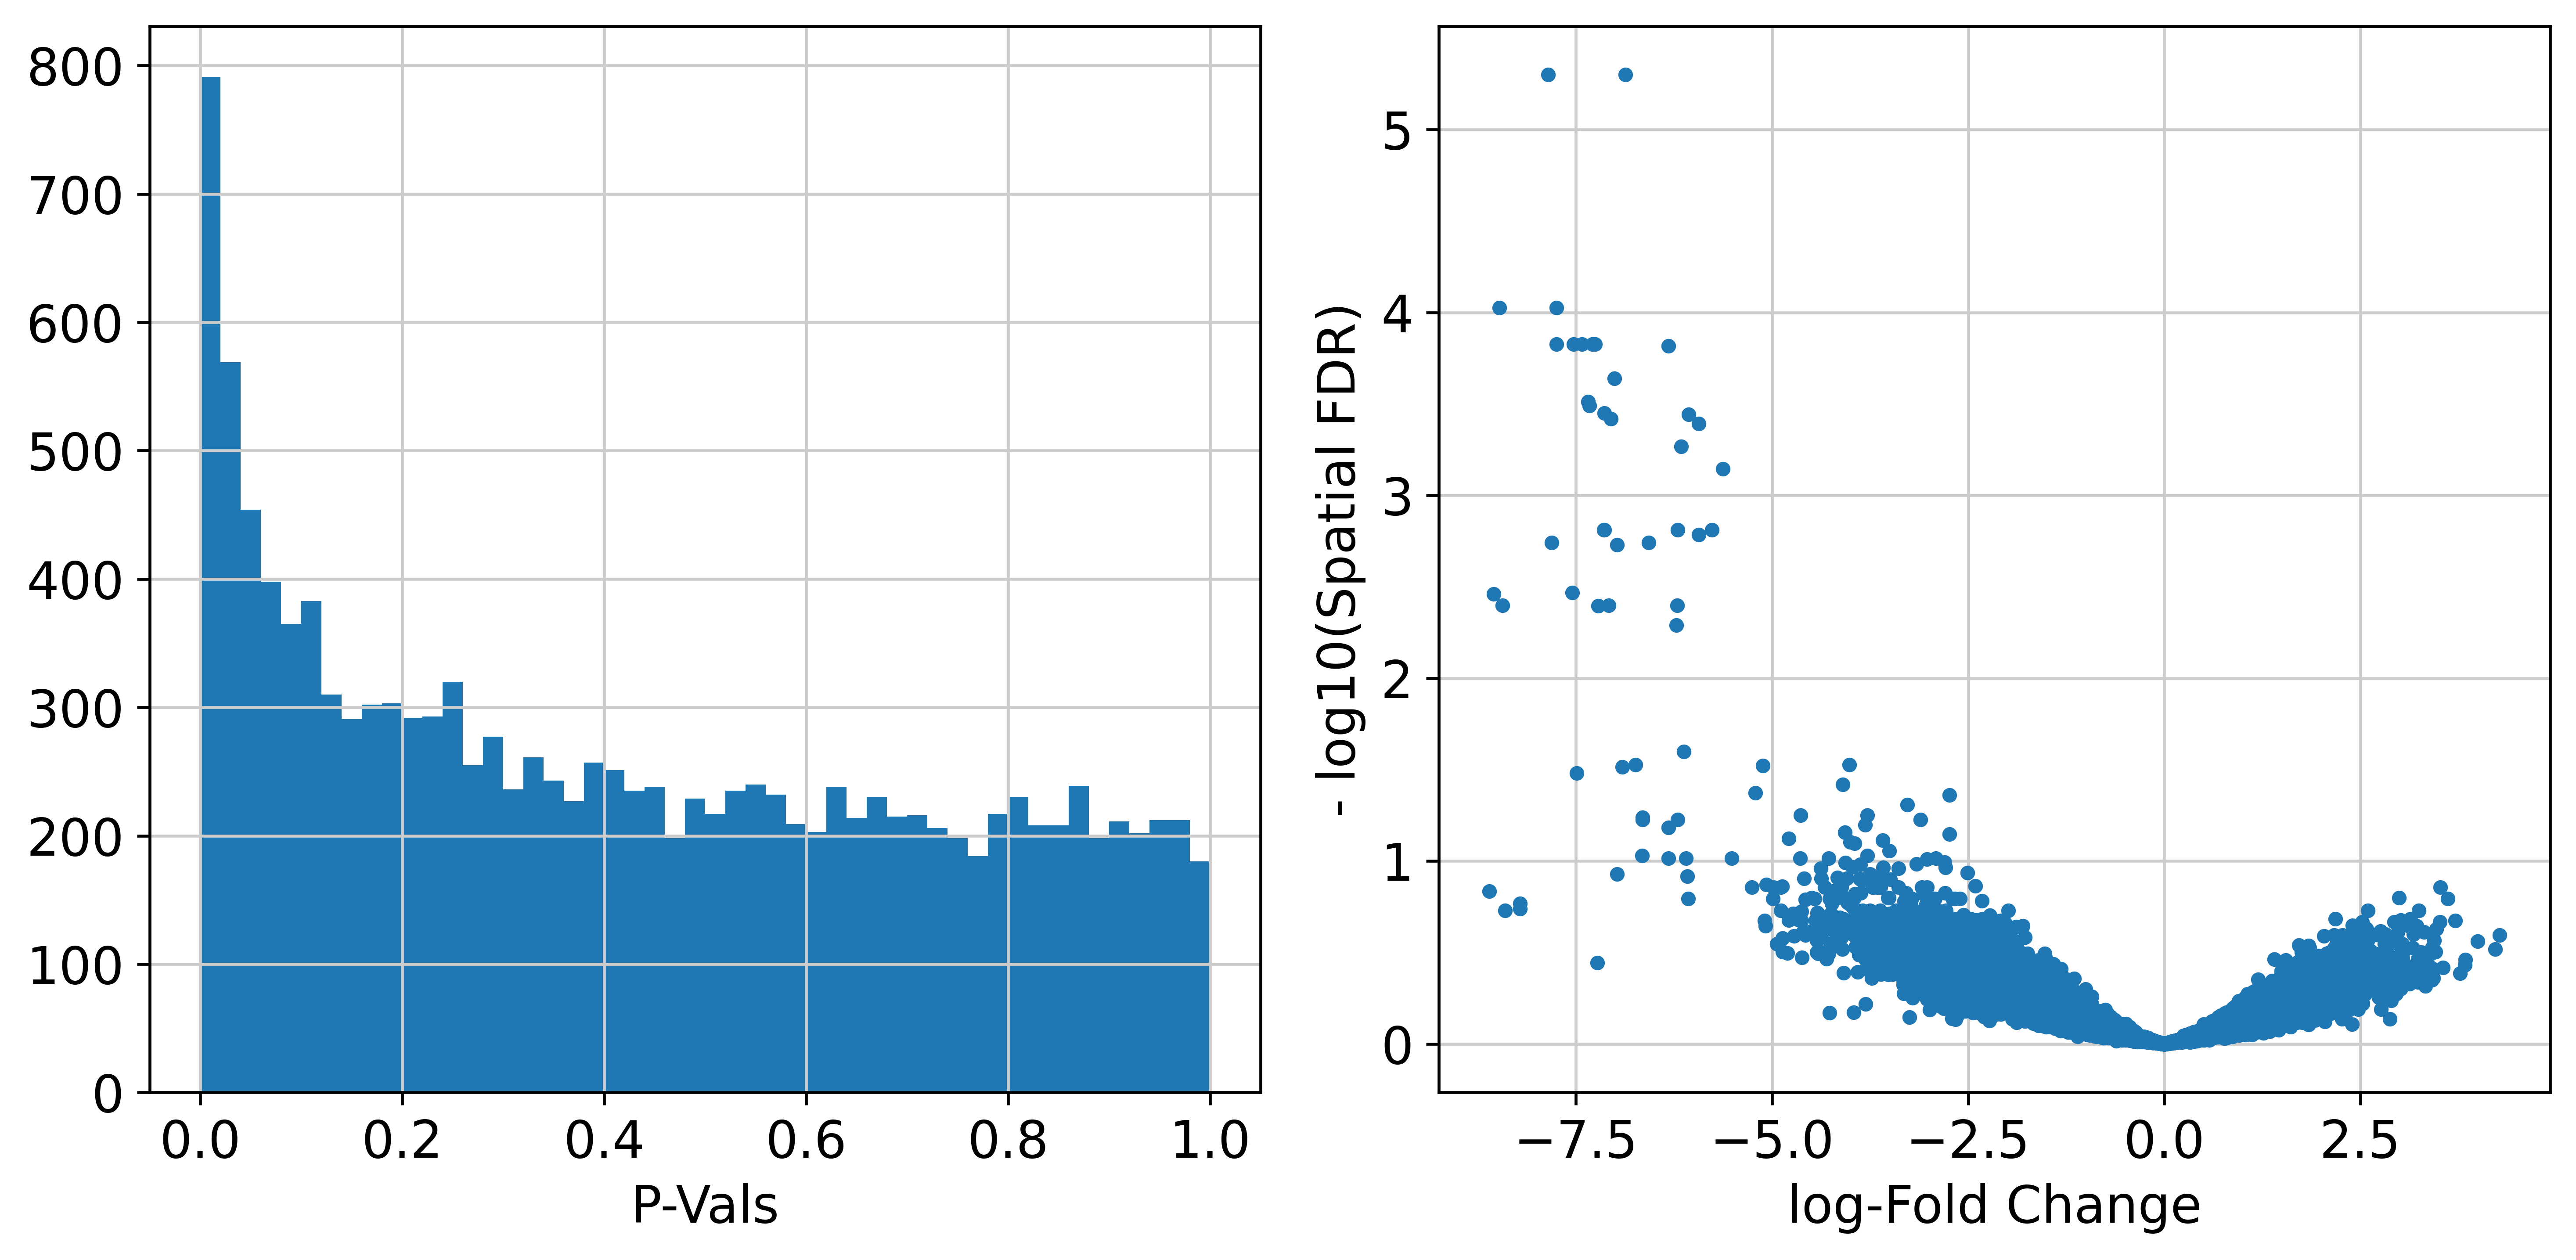

In [38]:
old_figsize = plt.rcParams["figure.figsize"]
plt.rcParams["figure.figsize"] = [10, 5]
plt.subplot(1, 2, 1)
plt.hist(mdata["milo"].var.PValue, bins=50)
plt.xlabel("P-Vals")
plt.subplot(1, 2, 2)
plt.plot(mdata["milo"].var.logFC, -np.log10(mdata["milo"].var.SpatialFDR), ".")
plt.xlabel("log-Fold Change")
plt.ylabel("- log10(Spatial FDR)")
plt.tight_layout()
plt.rcParams["figure.figsize"] = old_figsize

In [39]:
milo.build_nhood_graph(mdata)

In [40]:
plt.rcParams["figure.figsize"] = [4, 4]
milo.plot_nhood_graph(
    mdata,
    alpha=alpha,
    min_size=1,
    save='_milo_severe_vs_mild.svg',
)

saving figure to file figures/X_milo_graph_milo_severe_vs_mild.svg


In [41]:
milo.annotate_nhoods(mdata, anno_col="initial_clustering")

Text(0.5, 0, 'celltype fraction')

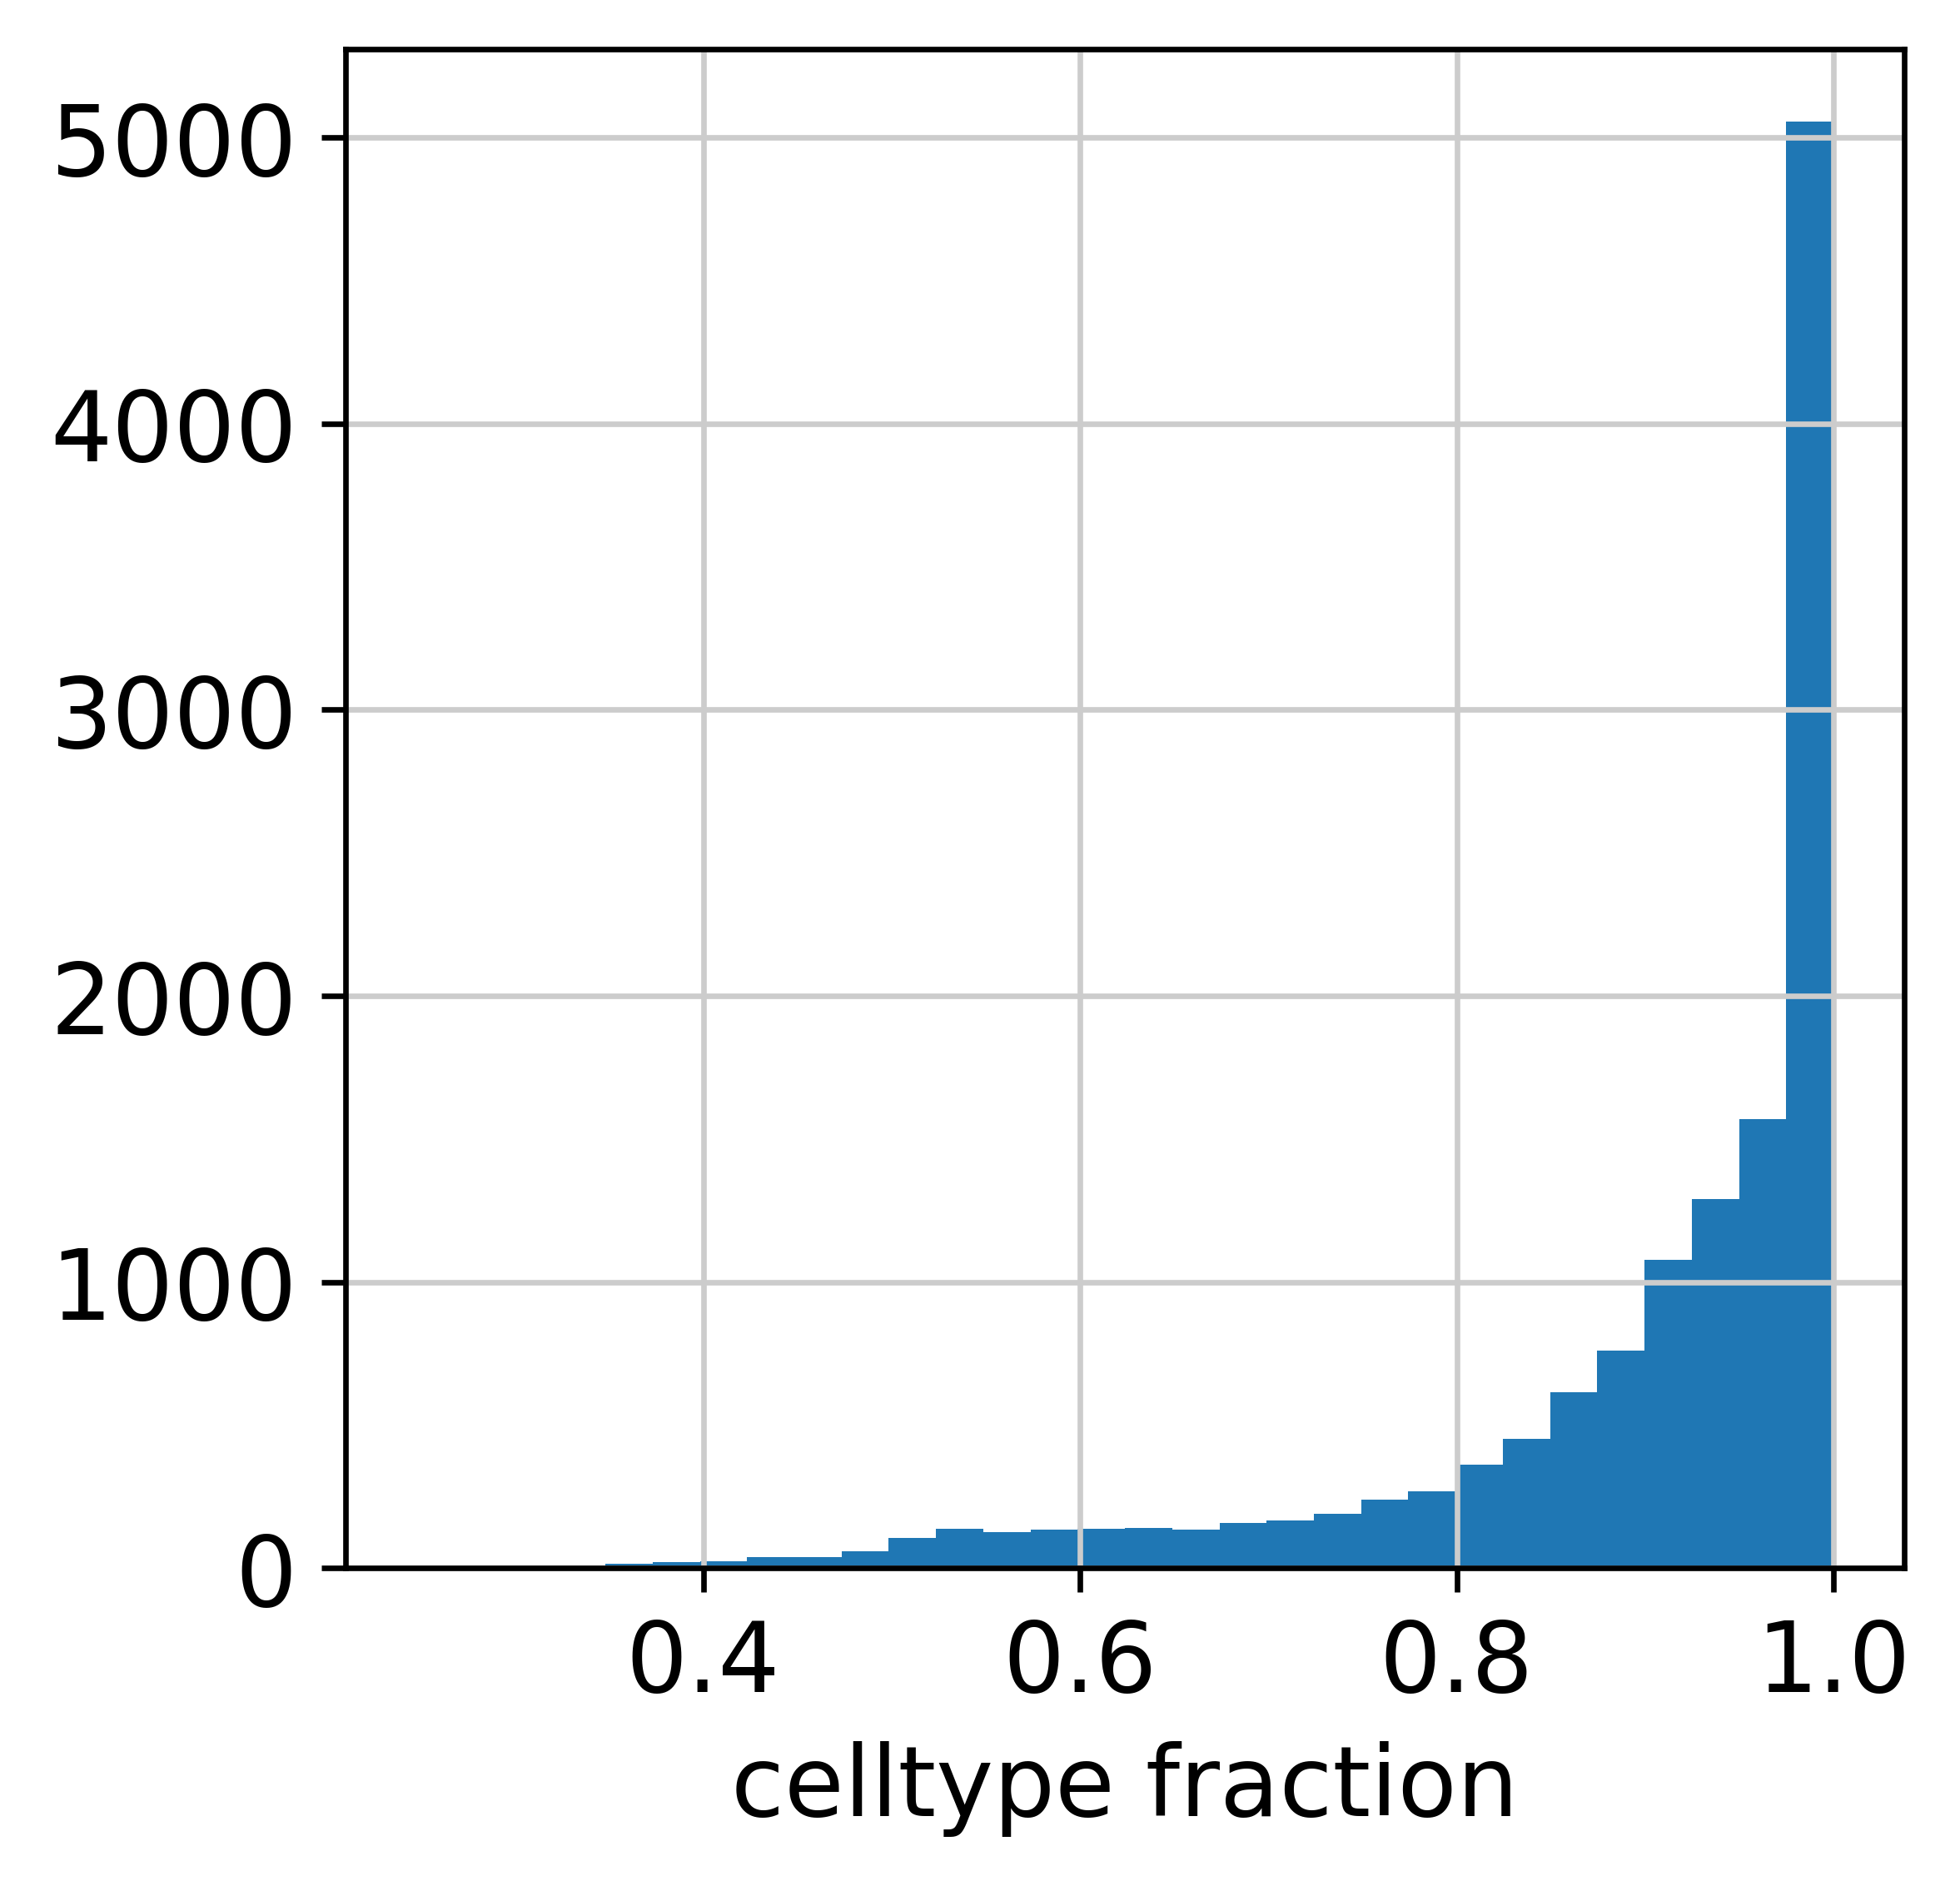

In [42]:
plt.hist(mdata["milo"].var["nhood_annotation_frac"], bins=30)
plt.xlabel("celltype fraction")

In [43]:
mdata["milo"].var["nhood_annotation"] = mdata["milo"].var["nhood_annotation"].cat.add_categories("Mixed")
mdata["milo"].var.loc[mdata["milo"].var["nhood_annotation_frac"] < 0.8, "nhood_annotation"] = "Mixed"

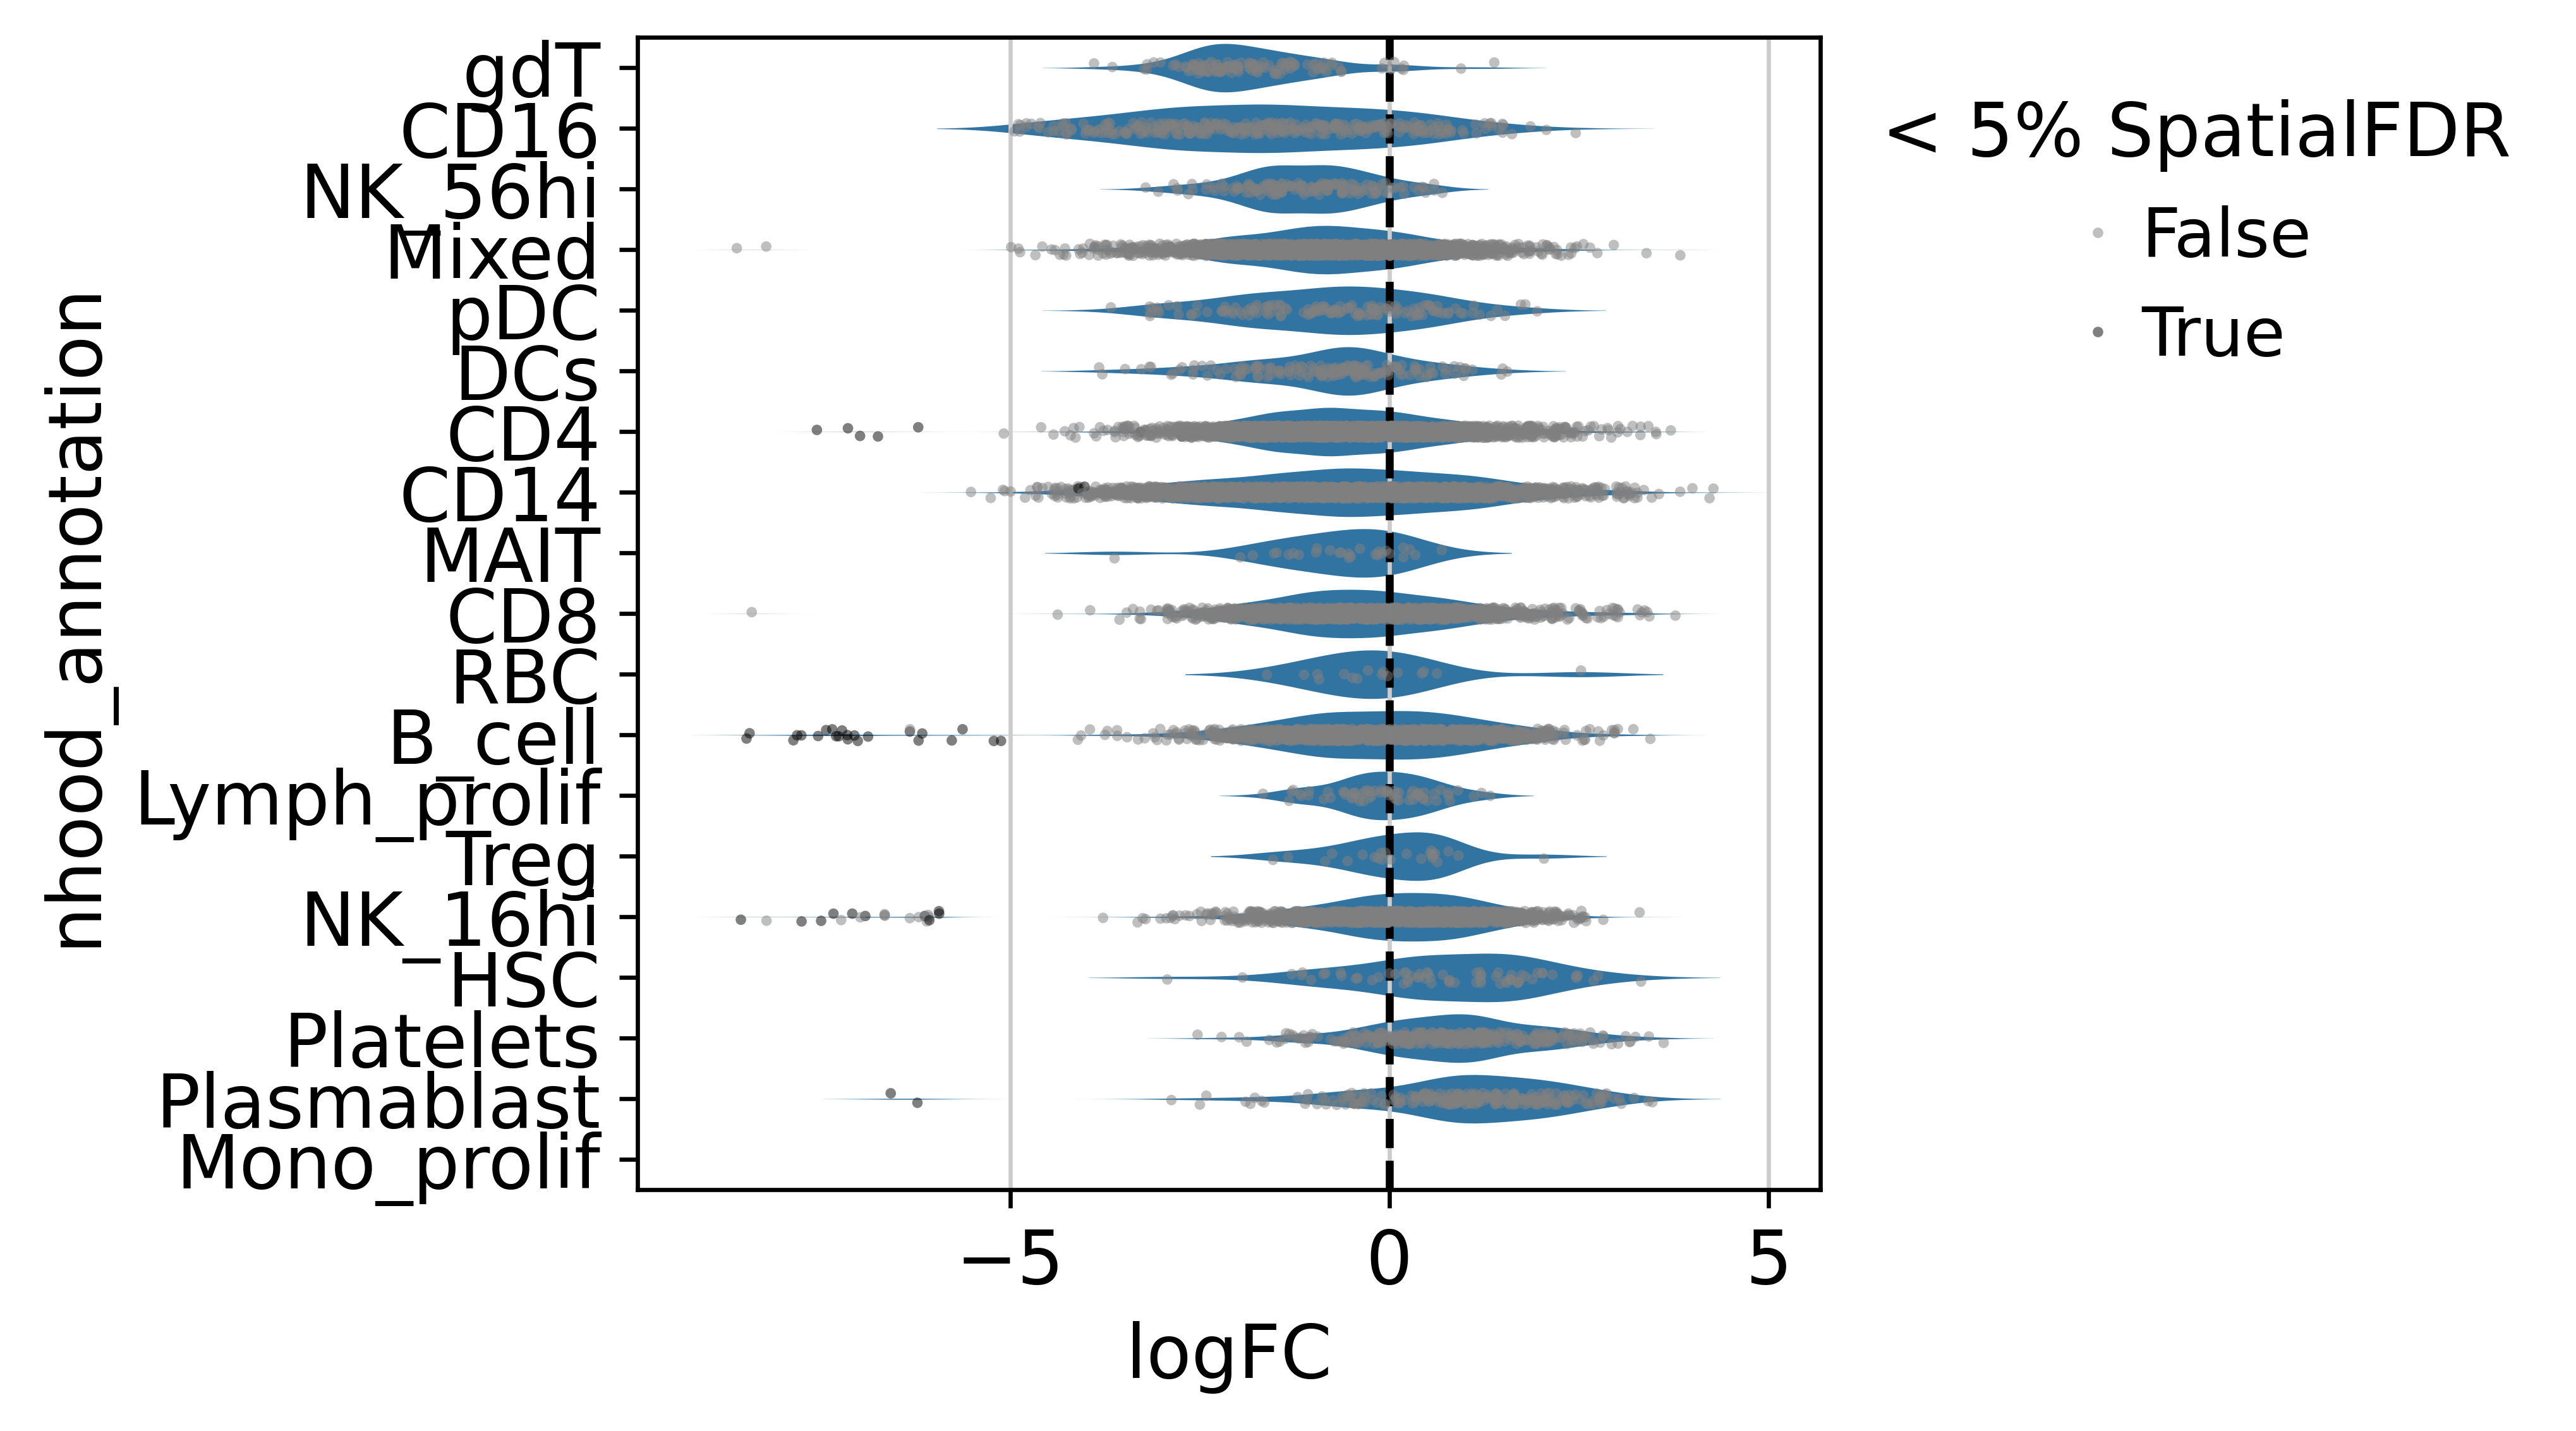

In [44]:
milo.plot_da_beeswarm(mdata, alpha=alpha, return_fig=True)
plt.savefig('figures/milo_severe_vs_mild_beeswarm.svg', bbox_inches='tight', dpi=300)

## Mild - Healthy

In [45]:
milo.da_nhoods(mdata, design="~Status_on_day_collection_summary", model_contrasts="Status_on_day_collection_summaryMild-Status_on_day_collection_summaryHealthy", solver="pydeseq2")

Fitting size factors...
/lustre/groups/ml01/workspace/anastasia.litinetskaya/mambaforge/envs/milo/lib/python3.12/site-packages/pydeseq2/dds.py:532: UserWarning: Every gene contains at least one zero, cannot compute log geometric means. Switching to iterative mode.
  self.fit_size_factors(


Using None as control genes, passed at DeseqDataSet initialization


Fitting dispersions...
... done in 1.95 seconds.

Fitting MAP dispersions...
... done in 1.76 seconds.

Fitting dispersions...
... done in 2.30 seconds.

Fitting MAP dispersions...
... done in 1.72 seconds.



Fitting dispersions...
... done in 2.38 seconds.

Fitting MAP dispersions...
... done in 1.73 seconds.

Fitting dispersions...
... done in 2.00 seconds.

Fitting MAP dispersions...
... done in 1.73 seconds.

Fitting dispersions...
... done in 1.99 seconds.

Fitting MAP dispersions...
... done in 4.16 seconds.

Fitting dispersions...
... done in 2.03 seconds.

Fitting MAP dispersions...
... done in 1.74 seconds.

Fitting dispersions...
... done in 2.03 seconds.

Fitting MAP dispersions...
... done in 1.78 seconds.

Fitting dispersions...
... done in 2.01 seconds.

Fitting MAP dispersions...
... done in 1.76 seconds.

Fitting dispersions...
... done in 3.85 seconds.

Fitting MAP dispersions...
... done in 1.82 seconds.

Fitting dispersions...
... done in 1.94 seconds.

Fitting MAP dispersions...
... done in 1.82 seconds.

Iterative size factor fitting did not converge.
... done in 351.14 seconds.

Fitting dispersions...
... done in 1.84 seconds.

Fitting dispersion trend curve...
/lustre

Log2 fold change & Wald test p-value: Status_on_day_collection_summary Mild vs Healthy
        baseMean  log2FoldChange     lfcSE      stat    pvalue      padj
0       4.239880        1.306732  1.096530  1.191697  0.233380  0.413620
1       3.718632       -1.023437  0.882661 -1.159491  0.246256  0.428101
2       1.531120       -1.407040  1.068869 -1.316383  0.188046       NaN
3       2.729174        0.075375  0.690337  0.109186  0.913055  0.949340
4      22.286343       -2.029511  0.903683 -2.245822  0.024715  0.113175
...          ...             ...       ...       ...       ...       ...
13327   5.918860        0.209262  1.011732  0.206835  0.836139  0.903337
13328   1.057179       -0.359799  0.911647 -0.394669  0.693087       NaN
13329  22.846750       -2.475169  1.037058 -2.386721  0.016999  0.094048
13330   7.032147       -1.380178  0.901063 -1.531722  0.125591  0.282288
13331   1.856053        1.944622  0.973467  1.997625  0.045757  0.156066

[13332 rows x 6 columns]


... done in 1.83 seconds.



In [46]:
mdata["milo"].var

,index_cell,kth_distance,SpatialFDR,Nhood_size,nhood_annotation,nhood_annotation_frac,logCPM,logFC,PValue,FDR
0,AAACCTGAGACCACGA-newcastle65,2.635731,0.434848,172.0,CD4,0.918605,4.239880,1.306732,0.233380,0.413620
1,AAACCTGGTTCGCGAC-newcastle65,2.423467,0.448113,229.0,CD4,0.960699,3.718632,-1.023437,0.246256,0.428101
2,AAACGGGGTTACAGAA-newcastle65,2.719470,0.386106,74.0,CD4,0.864865,1.531120,-1.407040,0.188046,NaN
3,AAACGGGTCATCGGAT-newcastle65,2.575334,0.951131,203.0,CD4,0.916256,2.729174,0.075375,0.913055,0.949340
4,AAAGCAACAGTTAACC-newcastle65,2.436827,0.137451,471.0,NK_16hi,0.993631,22.286343,-2.029511,0.024715,0.113175
...,...,...,...,...,...,...,...,...,...,...
13327,BGCV15_TGCACCTTCGCCAGCA-1,2.510799,0.906686,163.0,CD4,0.914110,5.918860,0.209262,0.836139,0.903337
13328,BGCV15_TGTGGTATCAGTTTGG-1,2.714978,0.815496,83.0,CD4,0.963855,1.057179,-0.359799,0.693087,NaN
13329,BGCV15_TTAGGCAAGCTAGCCC-1,2.534584,0.118526,362.0,NK_16hi,0.941989,22.846750,-2.475169,0.016999,0.094048
13330,BGCV15_TTCTACATCCGCGGTA-1,2.647649,0.307624,170.0,NK_16hi,1.000000,7.032147,-1.380178,0.125591,0.282288


In [47]:
# save milo testing results
mdata["milo"].var.to_csv('milo_mild_vs_healthy.csv')

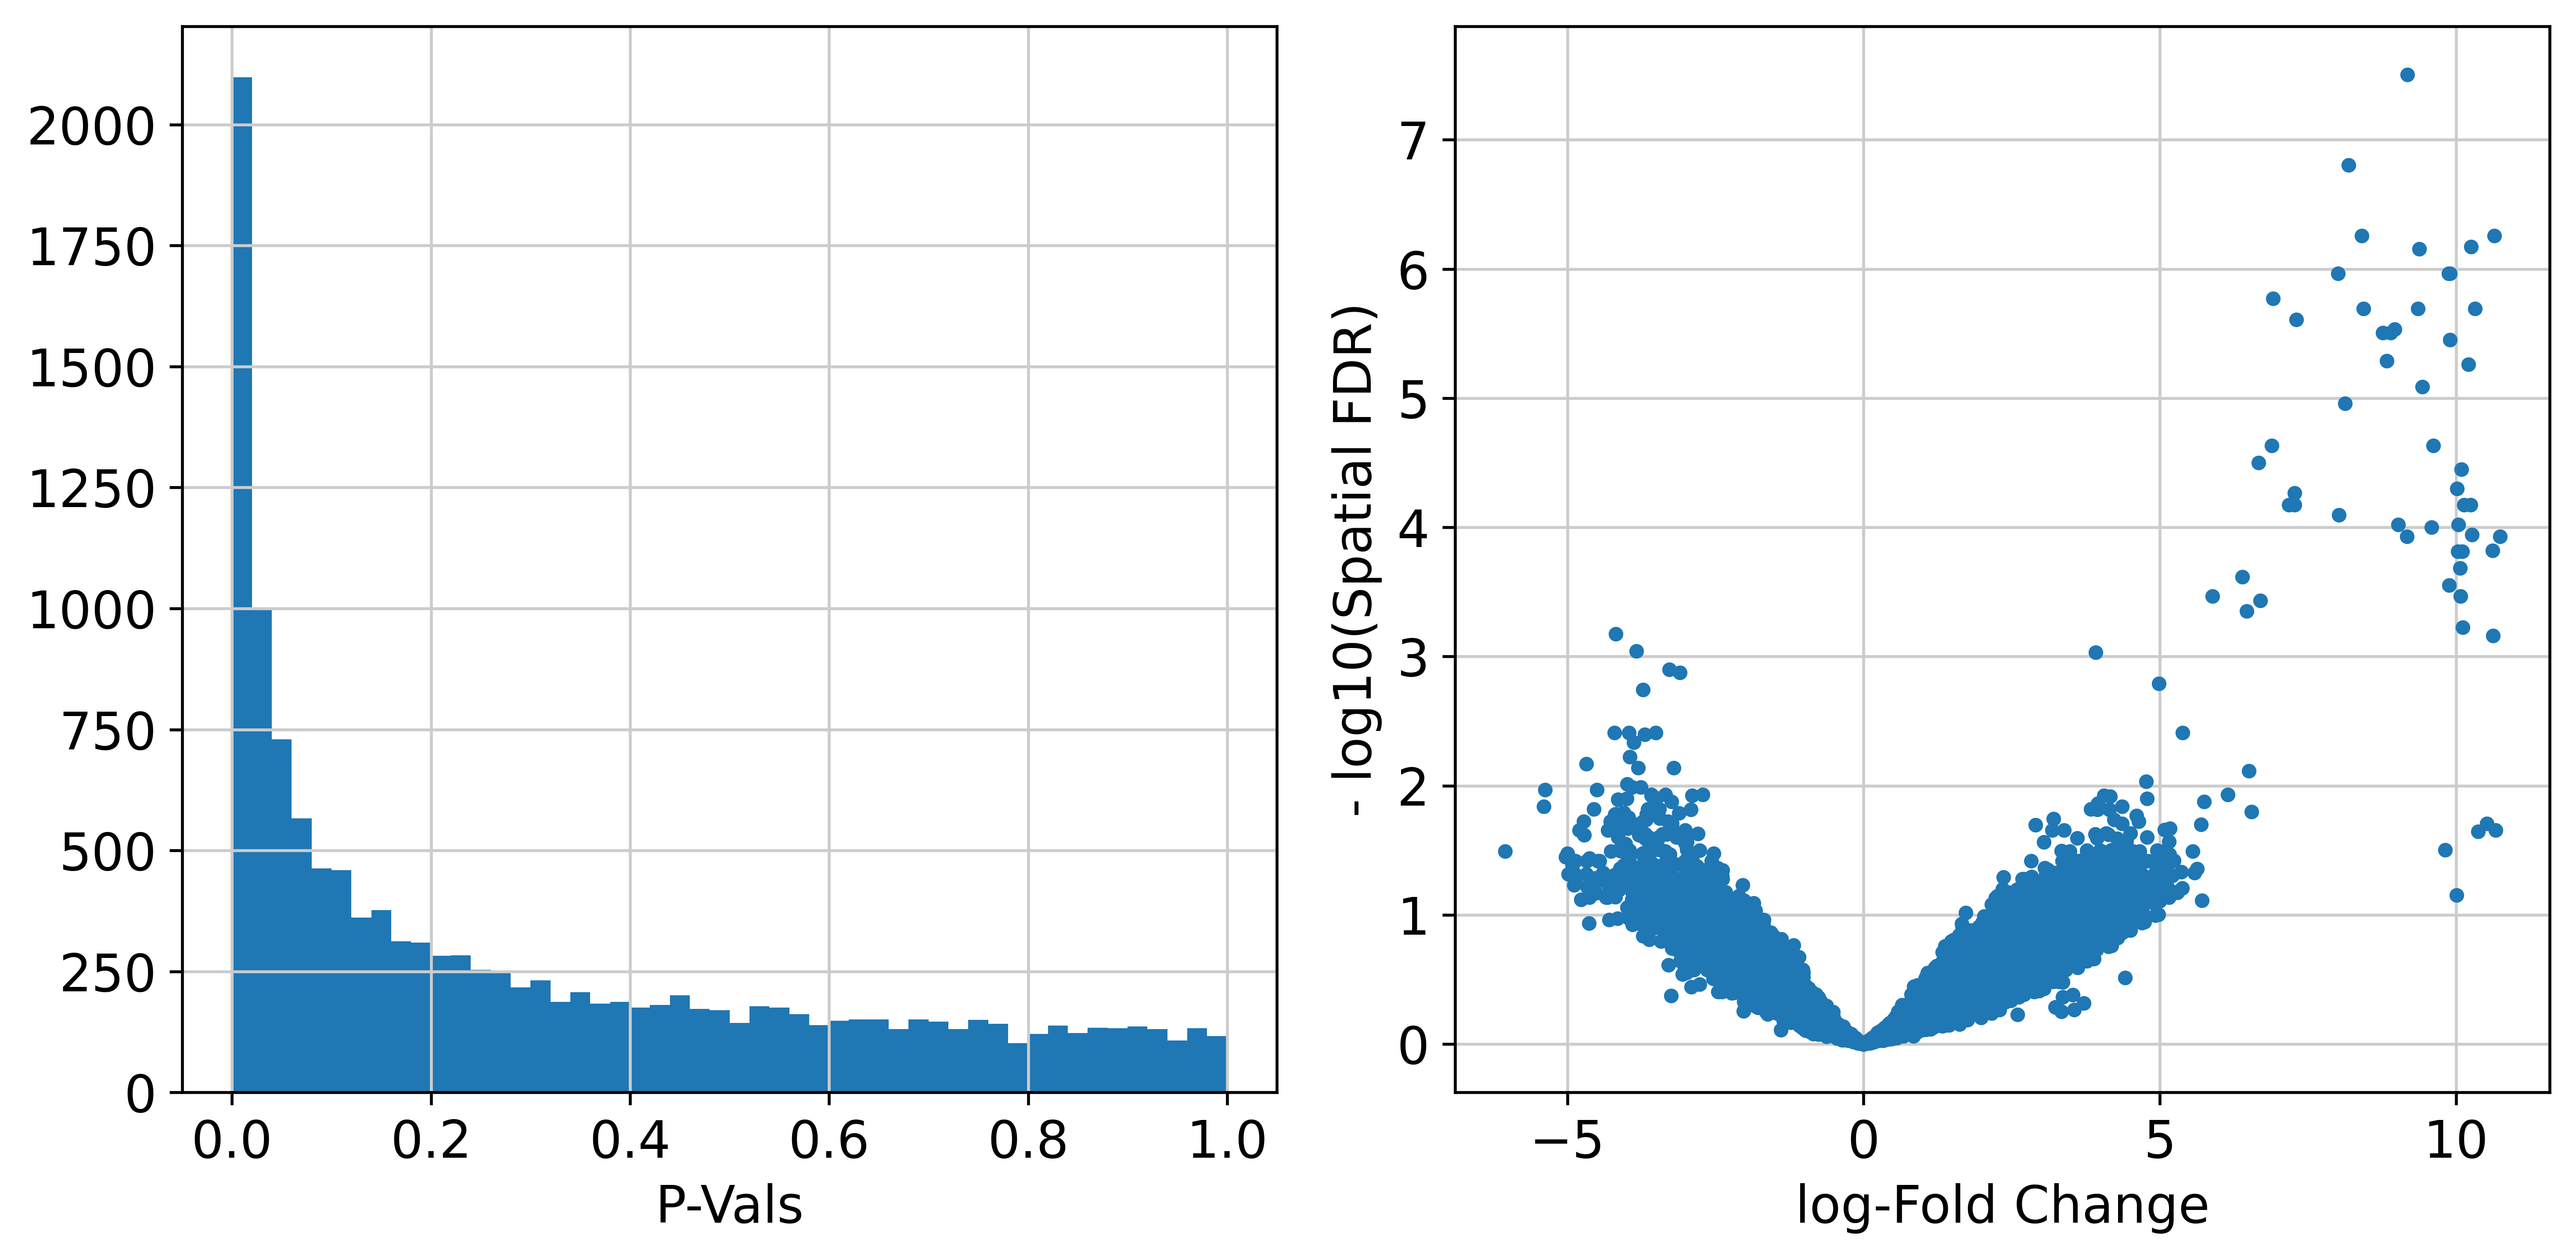

In [48]:
old_figsize = plt.rcParams["figure.figsize"]
plt.rcParams["figure.figsize"] = [10, 5]
plt.subplot(1, 2, 1)
plt.hist(mdata["milo"].var.PValue, bins=50)
plt.xlabel("P-Vals")
plt.subplot(1, 2, 2)
plt.plot(mdata["milo"].var.logFC, -np.log10(mdata["milo"].var.SpatialFDR), ".")
plt.xlabel("log-Fold Change")
plt.ylabel("- log10(Spatial FDR)")
plt.tight_layout()
plt.rcParams["figure.figsize"] = old_figsize

In [49]:
milo.build_nhood_graph(mdata)

In [50]:
plt.rcParams["figure.figsize"] = [4, 4]
milo.plot_nhood_graph(
    mdata,
    alpha=alpha,
    min_size=1,
    save='_milo_mild_vs_healthy.svg',
)

saving figure to file figures/X_milo_graph_milo_mild_vs_healthy.svg


In [51]:
milo.annotate_nhoods(mdata, anno_col="initial_clustering")

Text(0.5, 0, 'celltype fraction')

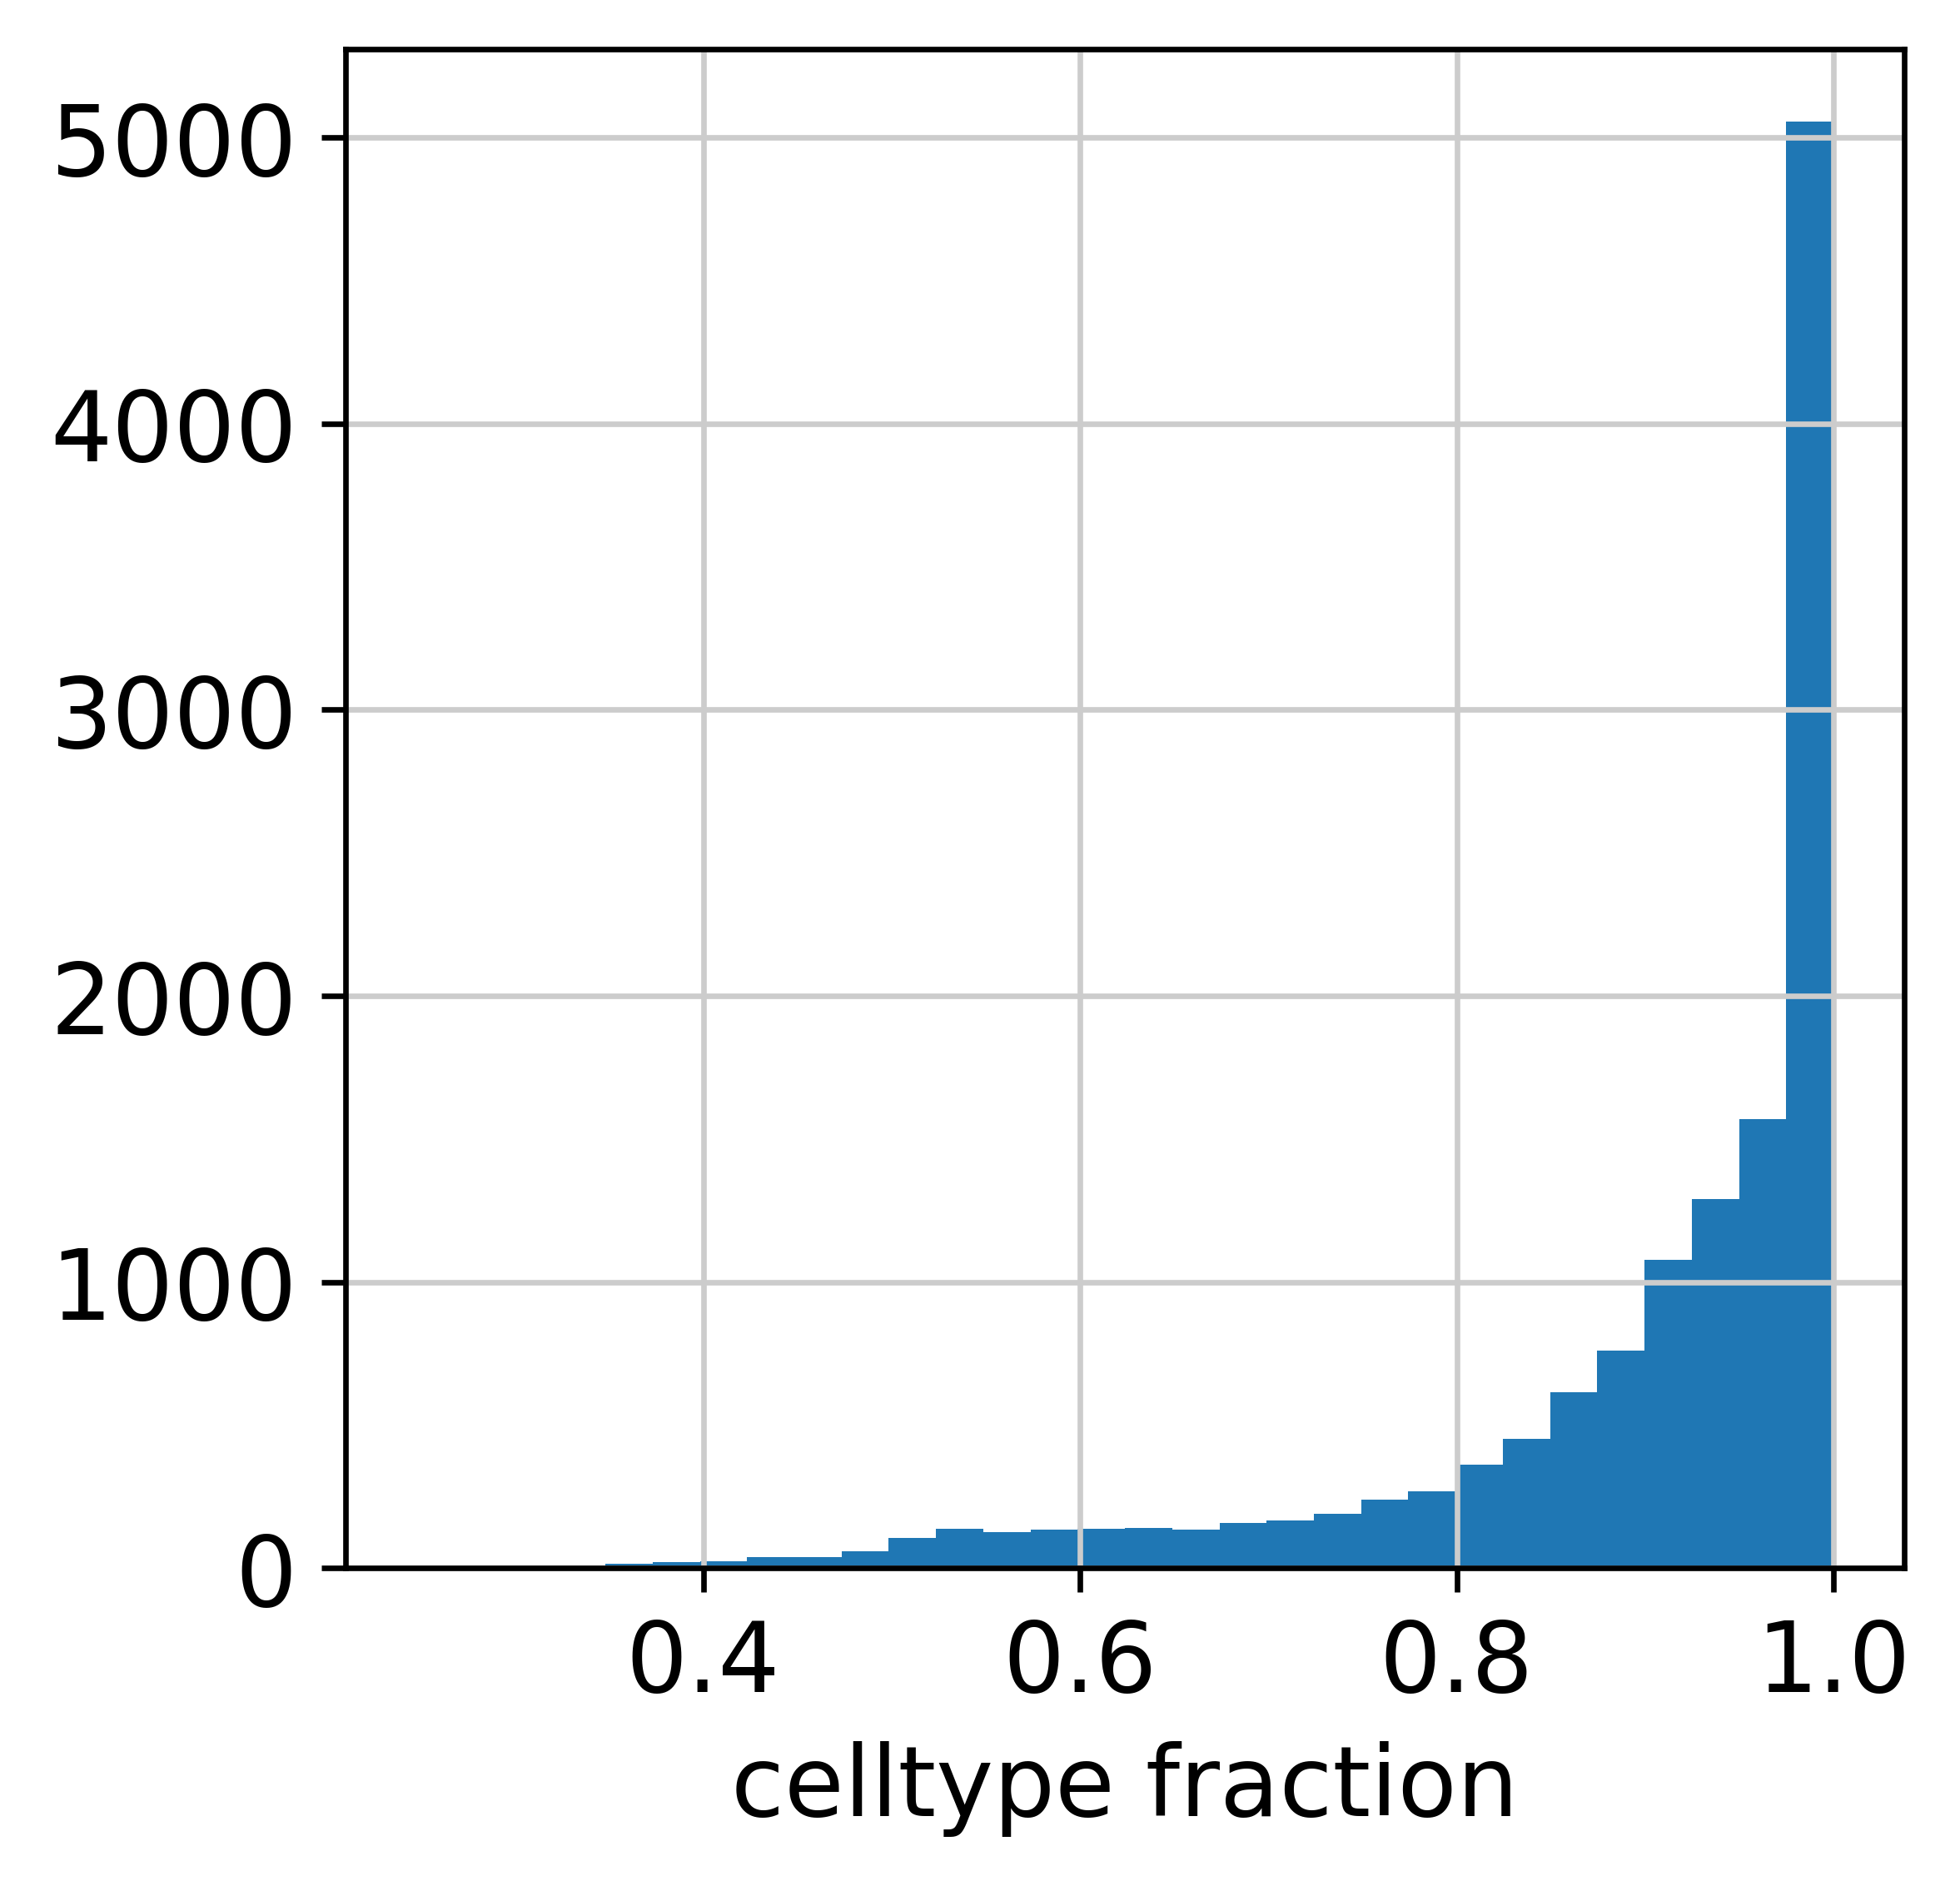

In [52]:
plt.hist(mdata["milo"].var["nhood_annotation_frac"], bins=30)
plt.xlabel("celltype fraction")

In [53]:
mdata["milo"].var["nhood_annotation"] = mdata["milo"].var["nhood_annotation"].cat.add_categories("Mixed")
mdata["milo"].var.loc[mdata["milo"].var["nhood_annotation_frac"] < 0.8, "nhood_annotation"] = "Mixed"

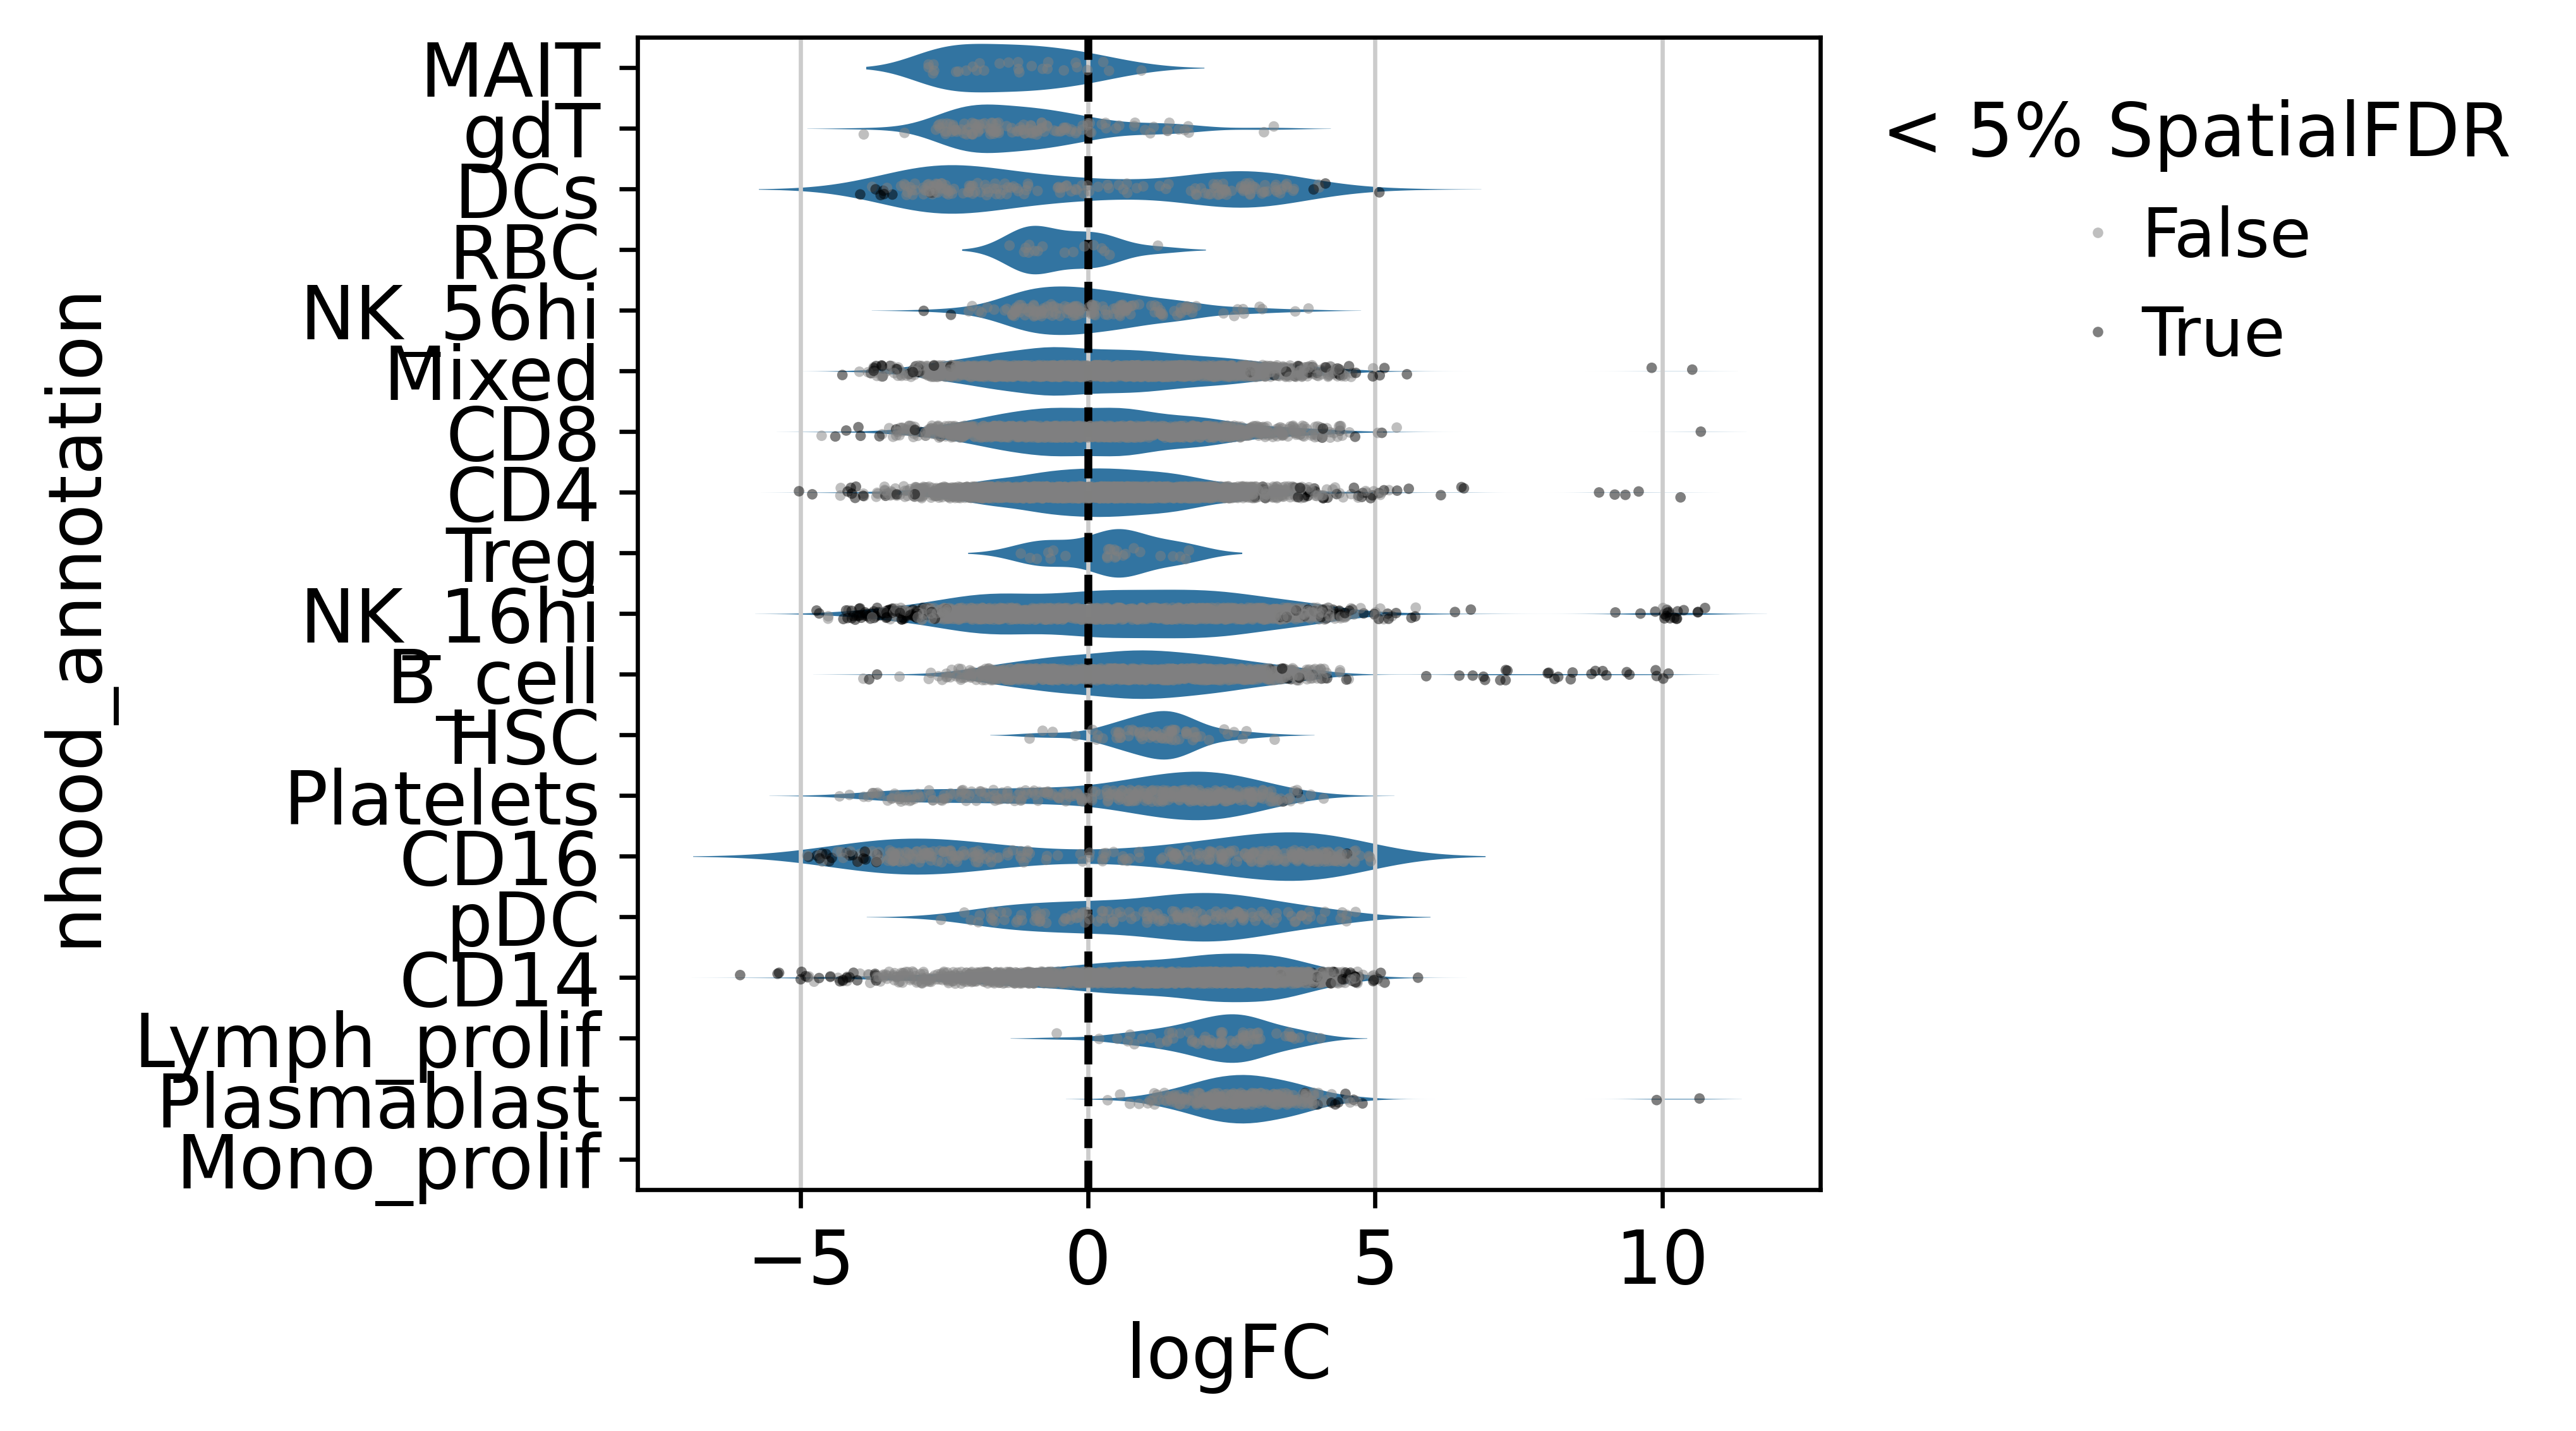

In [54]:
milo.plot_da_beeswarm(mdata, alpha=alpha, return_fig=True)
plt.savefig('figures/milo_mild_vs_healthy_beeswarm.svg', bbox_inches='tight', dpi=300)